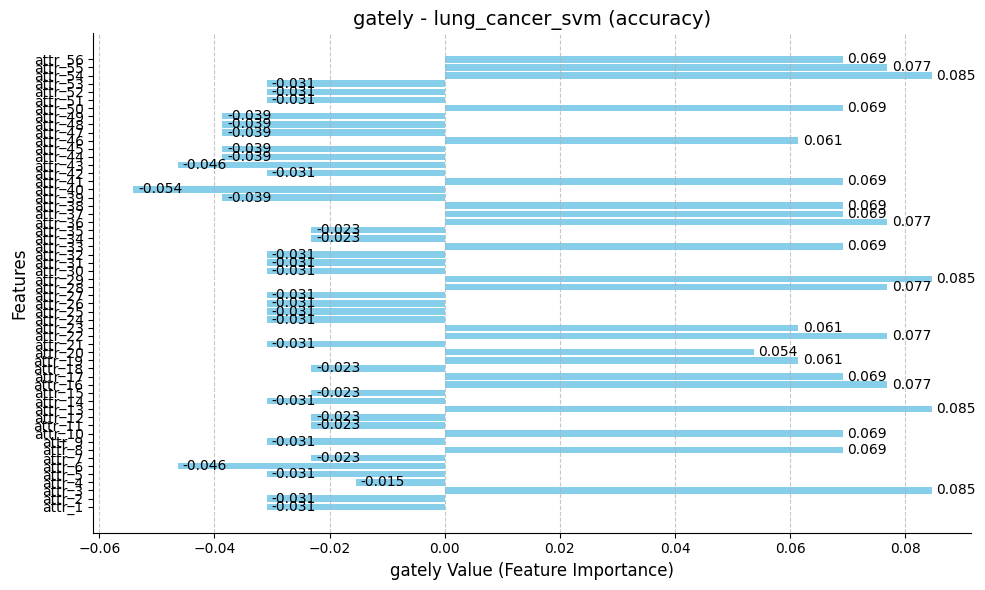

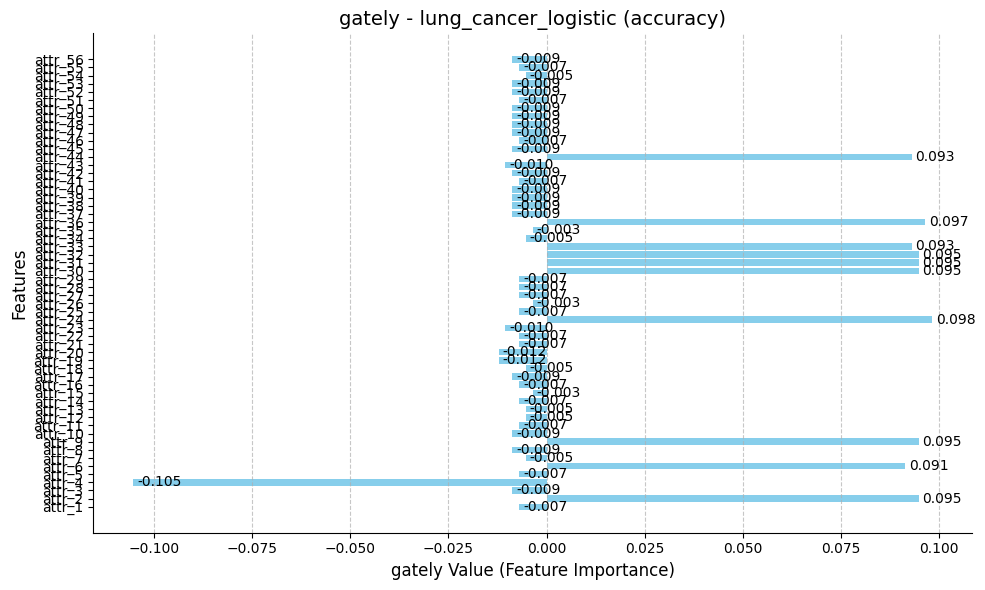

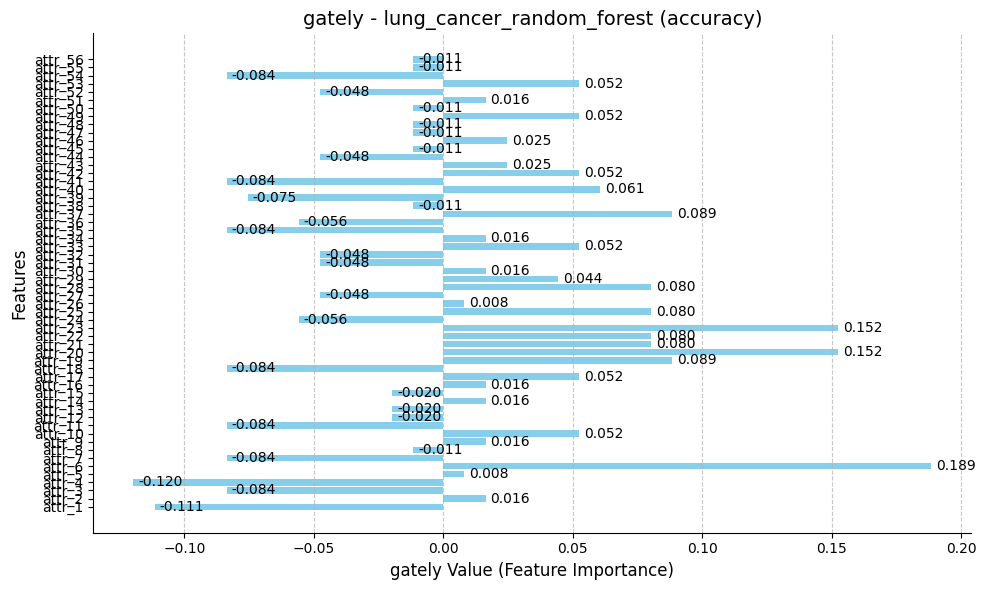

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
import sys, os

from scipy.stats import spearmanr, pearsonr
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error, r2_score, mean_absolute_error

# Add project root to sys.path (robust)
from pathlib import Path as _Path

HERE = _Path.cwd().resolve()
root = None
for p in [HERE] + list(HERE.parents):
    if (p / "gt_concepts").is_dir():
        root = p
        break
if root is None:
    raise RuntimeError(f"Could not find project root containing 'gt_concepts' from {HERE}")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from gt_concepts.gately_point import exact_gately_value
from models.train_model import get_model
from utils.plotting import plot_single_valuation

# Logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Config
DATASETS = ["lung_cancer"]  # can add "mi_complications"
MODEL_NAMES = ["svm", "logistic", "random_forest"]
SCORING = "accuracy"
RANDOM_STATE = 42

# Faithfulness curve settings
CURVE_STEPS = 20  # how many points in deletion curve (more = slower but smoother)

# Robustness settings
NOISE_LEVEL = 0.05
BOOTSTRAP_ROUNDS = 5  # increase to 10+ for stronger robustness estimates

BASE_OUTPUT_DIR = Path("./output/feature_valuation_uci_paper_eval")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset loaders
def load_lung_cancer():
    path = "../datasets/lung-cancer.data"
    df = pd.read_csv(path, header=None, na_values="?")

    y = df.iloc[:, 0].astype(int).values
    X_df = df.iloc[:, 1:]
    feature_names = [f"attr_{i}" for i in range(1, X_df.shape[1] + 1)]

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_mi_complications(binary_let_is=True):
    path = "../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    let_is = df.iloc[:, 123].astype(int).values
    y = (let_is != 0).astype(int) if binary_let_is else let_is

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_dataset(name: str):
    if name == "lung_cancer":
        return load_lung_cancer()
    elif name == "mi_complications":
        return load_mi_complications(binary_let_is=True)
    else:
        raise ValueError(f"Unknown dataset name: {name}")

# Utility + scorer
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)


class Utility:
    """
    v(S): train model on features S, evaluate on test.
    """
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer,
                 feature_names=None, random_state=42):
        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]

        if len(key) == 0:
            # majority baseline
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = score
            return score

        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = score
        return score


def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")

# Step 1: Multi-metric Faithfulness + Robustness
def loo_impacts(utility: Utility):
    n = len(utility.data)
    all_set = set(range(n))
    vN = utility(list(all_set))
    impacts = np.zeros(n)
    for i in range(n):
        vN_minus_i = utility(list(all_set - {i}))
        impacts[i] = vN - vN_minus_i
    return vN, impacts


def deletion_auc_score(utility: Utility, attribution: np.ndarray, steps: int = 20):
    """
    Perturbation faithfulness metric:
    - Remove features in descending attribution order
    - Track performance v(remaining)
    - Compute AUC of performance curve vs fraction removed

    IMPORTANT: For deletion evaluation, "better explanations" cause performance
    to drop faster => lower AUC. To make "higher = better", we return -AUC.
    """
    n = len(attribution)
    order = np.argsort(-attribution)  # high attribution first

    # fractions removed from 0 to 1
    fracs = np.linspace(0, 1, steps)
    scores = []

    full_set = list(range(n))
    for f in fracs:
        k_remove = int(round(f * n))
        removed = set(order[:k_remove].tolist())
        remaining = [j for j in full_set if j not in removed]
        scores.append(utility(remaining))

    scores = np.array(scores)
    auc = np.trapz(scores, fracs)  # area under performance curve
    return -float(auc)  # higher is better


def cosine(a, b):
    return float(np.dot(a, b) / ((np.linalg.norm(a) * np.linalg.norm(b)) + 1e-12))


def bootstrap_stability_cosine(base_utility: Utility, method_fn, rounds: int = 5):
    """
    Robustness metric:
    - resample training set with replacement
    - recompute attribution
    - compare to original attribution with cosine similarity
    Returns mean cosine over rounds.
    """
    X_train = base_utility.X_train
    y_train = base_utility.y_train
    X_test = base_utility.X_test
    y_test = base_utility.y_test
    model_name = base_utility.model_name
    scorer = base_utility.scorer
    feature_names = base_utility.data.data_names
    rs = base_utility.random_state

    # original attribution
    phi0 = method_fn(base_utility)

    cos_list = []
    n = X_train.shape[0]
    rng = np.random.default_rng(rs)

    for r in range(rounds):
        idx = rng.integers(0, n, size=n)
        Xb = X_train[idx]
        yb = y_train[idx]

        util_b = Utility(
            Xb, yb, X_test, y_test,
            model_name=model_name,
            scorer=scorer,
            feature_names=feature_names,
            random_state=rs + 1000 + r
        )
        phi_b = method_fn(util_b)
        cos_list.append(cosine(phi0, phi_b))

    return float(np.mean(cos_list))


def noise_stability_cosine(base_utility: Utility, method_fn, noise_level: float = 0.05):
    """
    Robustness metric:
    - add Gaussian noise to X_train
    - recompute attribution
    - cosine similarity with original
    """
    X_train = base_utility.X_train
    y_train = base_utility.y_train
    X_test = base_utility.X_test
    y_test = base_utility.y_test
    model_name = base_utility.model_name
    scorer = base_utility.scorer
    feature_names = base_utility.data.data_names
    rs = base_utility.random_state

    phi0 = method_fn(base_utility)

    noise = np.random.normal(0, noise_level * X_train.std(axis=0), X_train.shape)
    X_noisy = X_train + noise

    util_noisy = Utility(
        X_noisy, y_train, X_test, y_test,
        model_name=model_name,
        scorer=scorer,
        feature_names=feature_names,
        random_state=rs
    )
    phi_noisy = method_fn(util_noisy)
    return cosine(phi0, phi_noisy)

# Attribution methods (add more later)
def gately_method_fn(utility: Utility) -> np.ndarray:
    res = exact_gately_value(utility, options=None, progress=False)
    return np.array(res.values, dtype=float)

ATTRIBUTION_METHODS = {
    "gately": gately_method_fn,
}

# Step 2: Rank, don’t compare raw scores
def rank_methods(metric_df: pd.DataFrame, higher_is_better_cols):
    """
    metric_df: rows = methods, columns = metrics
    returns rank_df with same shape, 1 = best rank
    """
    rank_df = pd.DataFrame(index=metric_df.index)

    for col in metric_df.columns:
        higher = col in higher_is_better_cols
        # rank 1 = best
        rank_df[col] = metric_df[col].rank(ascending=not higher, method="average")

    return rank_df

# Step 3: Report mean rank μ̂ and disagreement σ̂
def rank_summary(rank_df: pd.DataFrame):
    return pd.DataFrame({
        "mean_rank_mu_hat": rank_df.mean(axis=1),
        "std_rank_sigma_hat": rank_df.std(axis=1, ddof=0)
    }).sort_values("mean_rank_mu_hat")

# Main
def main():
    scorer = get_scorer(SCORING)

    for dataset_name in DATASETS:
        X_train, X_test, y_train, y_test, feature_names = load_dataset(dataset_name)

        for model_name in MODEL_NAMES:
            logger.info("\n" + "=" * 70)
            logger.info(f"DATASET: {dataset_name} | MODEL: {model_name}")
            logger.info("=" * 70)

            OUTPUT_DIR = BASE_OUTPUT_DIR / f"{dataset_name}_{model_name}_results"
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

            utility = Utility(
                X_train, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            n_features = X_train.shape[1]
            vN, impacts = loo_impacts(utility)
            logger.info(f"  v(N) with all features ({SCORING}) = {vN:.4f}")

            # Compute attributions for all methods
            attributions = {}
            for mname, mfn in ATTRIBUTION_METHODS.items():
                logger.info(f"Computing attributions: {mname}")
                phi = mfn(utility)
                attributions[mname] = phi

                # Save per-feature values + plot
                df_vals = pd.DataFrame({
                    "method": mname,
                    "feature": feature_names,
                    "value": phi
                })
                df_vals.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_feature_valuations_{mname}.csv", index=False)

                try:
                    plot_single_valuation(
                        phi, feature_names,
                        method_name=mname,
                        title=f"{mname} - {dataset_name}_{model_name} ({SCORING})",
                        output_path=OUTPUT_DIR / f"{dataset_name}_{model_name}_{mname}.png"
                    )
                except Exception as e:
                    logger.warning(f"Plot failed for {mname}: {e}")

            # Step 1: Faithfulness metrics (multiple)
            faith_rows = []
            for mname, phi in attributions.items():
                sp, sp_p = spearmanr(phi, impacts)
                pe, pe_p = pearsonr(phi, impacts)
                del_score = deletion_auc_score(utility, phi, steps=CURVE_STEPS)

                faith_rows.append({
                    "method": mname,
                    "loo_spearman": float(sp),
                    "loo_pearson": float(pe),
                    "deletion_score_neg_auc": float(del_score),
                    "p_spearman": float(sp_p),
                    "p_pearson": float(pe_p),
                })

            faith_df = pd.DataFrame(faith_rows).set_index("method")
            faith_df.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_faithfulness_metrics_raw.csv")
            logger.info("\nFaithfulness metrics (raw):\n" + faith_df.to_string())

            # Step 1: Robustness metrics (multiple)
            rob_rows = []
            for mname, mfn in ATTRIBUTION_METHODS.items():
                noise_cos = noise_stability_cosine(utility, mfn, noise_level=NOISE_LEVEL)
                boot_cos = bootstrap_stability_cosine(utility, mfn, rounds=BOOTSTRAP_ROUNDS)

                rob_rows.append({
                    "method": mname,
                    "noise_cosine": float(noise_cos),
                    "bootstrap_cosine": float(boot_cos),
                })

            rob_df = pd.DataFrame(rob_rows).set_index("method")
            rob_df.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_robustness_metrics_raw.csv")
            logger.info("\nRobustness metrics (raw):\n" + rob_df.to_string())

            # Step 2: Rank per metric (not raw scores)
            # All these are "higher is better" by construction
            faith_higher_is_better = {"loo_spearman", "loo_pearson", "deletion_score_neg_auc"}
            rob_higher_is_better = {"noise_cosine", "bootstrap_cosine"}

            faith_rank = rank_methods(faith_df[["loo_spearman", "loo_pearson", "deletion_score_neg_auc"]],
                                      higher_is_better_cols=faith_higher_is_better)
            rob_rank = rank_methods(rob_df[["noise_cosine", "bootstrap_cosine"]],
                                    higher_is_better_cols=rob_higher_is_better)

            faith_rank.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_faithfulness_ranks.csv")
            rob_rank.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_robustness_ranks.csv")

            # Step 3: Mean rank μ̂ and disagreement σ̂
            faith_summary = rank_summary(faith_rank)
            rob_summary = rank_summary(rob_rank)

            faith_summary.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_faithfulness_rank_summary.csv")
            rob_summary.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_robustness_rank_summary.csv")

            logger.info("\nFaithfulness rank summary (μ̂, σ̂):\n" + faith_summary.to_string())
            logger.info("\nRobustness rank summary (μ̂, σ̂):\n" + rob_summary.to_string())

            logger.info(f"\nSaved paper-style evaluation outputs to: {OUTPUT_DIR}")
            logger.info("=" * 70)


if __name__ == "__main__":
    main()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
import sys

from scipy.stats import spearmanr, pearsonr
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error, r2_score, mean_absolute_error

# Add project root to sys.path (robust)
from pathlib import Path as _Path

HERE = _Path.cwd().resolve()
root = None
for p in [HERE] + list(HERE.parents):
    if (p / "gt_concepts").is_dir():
        root = p
        break
if root is None:
    raise RuntimeError(f"Could not find project root containing 'gt_concepts' from {HERE}")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
print("Project root added to sys.path:", root)

# Project imports
from models.train_model import get_model
from utils.plotting import plot_single_valuation

# Attribution methods
from gt_concepts.gately_point import exact_gately_value
from gt_concepts.least_core import montecarlo_least_core
from gt_concepts.shapley import montecarlo_shapley_value

# Logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Config
DATASETS = ["mi_complications"]  # add "mi_complications" when ready
MODEL_NAMES = ["svm", "logistic", "random_forest"]
SCORING = "accuracy"
RANDOM_STATE = 42

BASE_OUTPUT_DIR = Path("./output/feature_valuation_uci_paper_eval_multi_master")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CURVE_STEPS = 25

NOISE_LEVEL = 0.05
BOOTSTRAP_ROUNDS = 10

SHAPLEY_MC_ITERS = 100

LEAST_CORE_MC_ITERS = 300
LEAST_CORE_EPSILON = 1e-6

LEAST_CORE_SOLVER_OPTS = {
    "solver": "SCS",
    "max_iters": 25000,
    "eps": 1e-6,
    "verbose": False
}


# Dataset loaders
def load_lung_cancer():
    path = "../datasets/lung-cancer.data"
    df = pd.read_csv(path, header=None, na_values="?")

    y = df.iloc[:, 0].astype(int).values
    X_df = df.iloc[:, 1:]
    feature_names = [f"attr_{i}" for i in range(1, X_df.shape[1] + 1)]

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_mi_complications(binary_let_is=True):
    path = "../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    let_is = df.iloc[:, 123].astype(int).values
    y = (let_is != 0).astype(int) if binary_let_is else let_is

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_dataset(name: str):
    if name == "lung_cancer":
        return load_lung_cancer()
    elif name == "mi_complications":
        return load_mi_complications(binary_let_is=True)
    else:
        raise ValueError(f"Unknown dataset name: {name}")

# Utility + scorer
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)


class Utility:
    """
    v(S): train model on features S, evaluate on test.
    Includes caching for speed.
    """
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer,
                 feature_names=None, random_state=42):
        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]

        if len(key) == 0:
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = score
            return score

        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = score
        return score


def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")

# Metrics helpers
def loo_impacts(utility: Utility):
    n = len(utility.data)
    all_set = set(range(n))
    vN = utility(list(all_set))
    impacts = np.zeros(n)
    for i in range(n):
        vN_minus_i = utility(list(all_set - {i}))
        impacts[i] = vN - vN_minus_i
    return vN, impacts


def _auc_for_removal_order(utility: Utility, order: np.ndarray, steps: int):
    n = len(order)
    full_set = list(range(n))
    fracs = np.linspace(0, 1, steps)
    scores = []
    for f in fracs:
        k_remove = int(round(f * n))
        removed = set(order[:k_remove].tolist())
        remaining = [j for j in full_set if j not in removed]
        scores.append(utility(remaining))
    return float(np.trapezoid(np.array(scores), fracs))


def deletion_auc_drop(utility: Utility, attribution: np.ndarray, steps: int = 25, rng_seed: int = 42):
    """
    Deletion faithfulness (paper-friendly, positive):
      AUC_random - AUC_attr
    IMPORTANT CHANGE: use abs(attribution) for ordering (magnitude of importance).
    """
    n = len(attribution)
    order_attr = np.argsort(-np.abs(attribution))
    rng = np.random.default_rng(rng_seed)
    order_rand = rng.permutation(n)

    auc_attr = _auc_for_removal_order(utility, order_attr, steps)
    auc_rand = _auc_for_removal_order(utility, order_rand, steps)
    return float(auc_rand - auc_attr)


def _auc_for_insertion_order(utility: Utility, order: np.ndarray, steps: int):
    n = len(order)
    fracs = np.linspace(0, 1, steps)
    scores = []
    for f in fracs:
        k_add = int(round(f * n))
        chosen = order[:k_add].tolist()
        scores.append(utility(chosen))
    return float(np.trapezoid(np.array(scores), fracs))


def insertion_auc_gain(utility: Utility, attribution: np.ndarray, steps: int = 25, rng_seed: int = 42):
    """
    Insertion faithfulness (paper-friendly, positive):
      AUC_attr - AUC_random
    IMPORTANT CHANGE: use abs(attribution) for ordering (magnitude of importance).
    """
    n = len(attribution)
    order_attr = np.argsort(-np.abs(attribution))
    rng = np.random.default_rng(rng_seed)
    order_rand = rng.permutation(n)

    auc_attr = _auc_for_insertion_order(utility, order_attr, steps)
    auc_rand = _auc_for_insertion_order(utility, order_rand, steps)
    return float(auc_attr - auc_rand)


def cosine(a, b):
    return float(np.dot(a, b) / ((np.linalg.norm(a) * np.linalg.norm(b)) + 1e-12))


def noise_stability_cosine(base_utility: Utility, method_fn, noise_level: float = 0.05):
    phi0 = method_fn(base_utility)

    X_train = base_utility.X_train
    noise = np.random.normal(0, noise_level * X_train.std(axis=0), X_train.shape)
    X_noisy = X_train + noise

    util_noisy = Utility(
        X_noisy, base_utility.y_train, base_utility.X_test, base_utility.y_test,
        model_name=base_utility.model_name,
        scorer=base_utility.scorer,
        feature_names=base_utility.data.data_names,
        random_state=base_utility.random_state
    )
    phi_noisy = method_fn(util_noisy)
    return cosine(phi0, phi_noisy)


def bootstrap_stability_cosine(base_utility: Utility, method_fn, rounds: int = 10):
    X_train = base_utility.X_train
    y_train = base_utility.y_train
    X_test = base_utility.X_test
    y_test = base_utility.y_test

    phi0 = method_fn(base_utility)

    rng = np.random.default_rng(base_utility.random_state)
    n = X_train.shape[0]
    cos_list = []
    for r in range(rounds):
        idx = rng.integers(0, n, size=n)
        Xb = X_train[idx]
        yb = y_train[idx]

        util_b = Utility(
            Xb, yb, X_test, y_test,
            model_name=base_utility.model_name,
            scorer=base_utility.scorer,
            feature_names=base_utility.data.data_names,
            random_state=base_utility.random_state + 1000 + r
        )
        phi_b = method_fn(util_b)
        cos_list.append(cosine(phi0, phi_b))

    return float(np.mean(cos_list))

# Attribution methods
def gately_method_fn(utility: Utility) -> np.ndarray:
    res = exact_gately_value(utility, options=None, progress=False)
    return np.array(res.values, dtype=float)


def least_core_mc_method_fn(utility: Utility) -> np.ndarray:
    res = montecarlo_least_core(
        utility,
        n_iterations=LEAST_CORE_MC_ITERS,
        epsilon=LEAST_CORE_EPSILON,
        options=LEAST_CORE_SOLVER_OPTS,
        progress=False
    )
    return np.array(res.values, dtype=float)


def shapley_mc_method_fn(utility: Utility) -> np.ndarray:
    res = montecarlo_shapley_value(
        utility,
        n_iterations=SHAPLEY_MC_ITERS,
        options=None,
        progress=False
    )
    return np.array(res.values, dtype=float)


ATTRIBUTION_METHODS = {
    "gately": gately_method_fn,
    "least_core_mc": least_core_mc_method_fn,
    "mc_shapley": shapley_mc_method_fn,
}

# Ranking + summaries (paper steps 2 & 3)
def rank_methods(metric_df: pd.DataFrame, higher_is_better_cols):
    rank_df = pd.DataFrame(index=metric_df.index)
    for col in metric_df.columns:
        higher = col in higher_is_better_cols
        rank_df[col] = metric_df[col].rank(ascending=not higher, method="average")
    return rank_df


def rank_summary(rank_df: pd.DataFrame):
    return pd.DataFrame({
        "mean_rank_mu_hat": rank_df.mean(axis=1),
        "std_rank_sigma_hat": rank_df.std(axis=1, ddof=0)
    }).sort_values("mean_rank_mu_hat")

# Main (MASTER CSV aggregation)
def main():
    scorer = get_scorer(SCORING)

    # MASTER collectors
    master_rows_faith = []
    master_rows_rob = []
    master_rows_faith_rank = []
    master_rows_rob_rank = []
    master_rows_faith_summary = []
    master_rows_rob_summary = []

    for dataset_name in DATASETS:
        X_train, X_test, y_train, y_test, feature_names = load_dataset(dataset_name)

        for model_name in MODEL_NAMES:
            logger.info("\n" + "=" * 70)
            logger.info(f"DATASET: {dataset_name} | MODEL: {model_name}")
            logger.info("=" * 70)

            OUTPUT_DIR = BASE_OUTPUT_DIR / f"{dataset_name}_{model_name}_results"
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

            utility = Utility(
                X_train, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            vN, impacts = loo_impacts(utility)
            logger.info(f"  v(N) with all features ({SCORING}) = {vN:.4f}")

            # Compute attributions
            attributions = {}
            for mname, mfn in ATTRIBUTION_METHODS.items():
                logger.info(f"Computing attributions: {mname}")
                phi = mfn(utility)
                attributions[mname] = phi

                df_vals = pd.DataFrame({"method": mname, "feature": feature_names, "value": phi})
                df_vals.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_feature_valuations_{mname}.csv", index=False)

                try:
                    plot_single_valuation(
                        phi, feature_names,
                        method_name=mname,
                        title=f"{mname} - {dataset_name}_{model_name} ({SCORING})",
                        output_path=OUTPUT_DIR / f"{dataset_name}_{model_name}_{mname}.png"
                    )
                except Exception as e:
                    logger.warning(f"Plot failed for {mname}: {e}")

            # Step 1: Faithfulness metrics
            faith_rows = []
            for mname, phi in attributions.items():
                sp, sp_p = spearmanr(phi, impacts)
                pe, pe_p = pearsonr(phi, impacts)

                del_drop = deletion_auc_drop(utility, phi, steps=CURVE_STEPS, rng_seed=RANDOM_STATE)
                ins_gain = insertion_auc_gain(utility, phi, steps=CURVE_STEPS, rng_seed=RANDOM_STATE)

                row = {
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": mname,
                    "loo_spearman": float(sp),
                    "loo_pearson": float(pe),
                    "deletion_auc_drop": float(del_drop),
                    "insertion_auc_gain": float(ins_gain),
                    "p_spearman": float(sp_p),
                    "p_pearson": float(pe_p),
                    "vN": float(vN),
                }
                faith_rows.append(row)
                master_rows_faith.append(row)

            faith_df = pd.DataFrame(faith_rows).set_index("method")
            faith_df.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_faithfulness_metrics_raw.csv")
            logger.info("\nFaithfulness metrics (raw):\n" + faith_df.to_string())

            # Step 1: Robustness metrics
            rob_rows = []
            for mname, mfn in ATTRIBUTION_METHODS.items():
                noise_cos = noise_stability_cosine(utility, mfn, noise_level=NOISE_LEVEL)
                boot_cos = bootstrap_stability_cosine(utility, mfn, rounds=BOOTSTRAP_ROUNDS)

                row = {
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": mname,
                    "noise_cosine": float(noise_cos),
                    "bootstrap_cosine": float(boot_cos),
                }
                rob_rows.append(row)
                master_rows_rob.append(row)

            rob_df = pd.DataFrame(rob_rows).set_index("method")
            rob_df.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_robustness_metrics_raw.csv")
            logger.info("\nRobustness metrics (raw):\n" + rob_df.to_string())

            # Step 2: Rank per metric
            faith_metric_cols = ["loo_spearman", "loo_pearson", "deletion_auc_drop", "insertion_auc_gain"]
            rob_metric_cols = ["noise_cosine", "bootstrap_cosine"]

            faith_rank = rank_methods(faith_df[faith_metric_cols], higher_is_better_cols=set(faith_metric_cols))
            rob_rank = rank_methods(rob_df[rob_metric_cols], higher_is_better_cols=set(rob_metric_cols))

            faith_rank.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_faithfulness_ranks.csv")
            rob_rank.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_robustness_ranks.csv")

            for method in faith_rank.index:
                r = {"dataset": dataset_name, "model": model_name, "method": method}
                r.update({f"rank_{c}": float(faith_rank.loc[method, c]) for c in faith_metric_cols})
                master_rows_faith_rank.append(r)

            for method in rob_rank.index:
                r = {"dataset": dataset_name, "model": model_name, "method": method}
                r.update({f"rank_{c}": float(rob_rank.loc[method, c]) for c in rob_metric_cols})
                master_rows_rob_rank.append(r)

            # Step 3: Mean rank μ̂ and disagreement σ̂
            faith_summary = rank_summary(faith_rank)
            rob_summary = rank_summary(rob_rank)

            faith_summary.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_faithfulness_rank_summary.csv")
            rob_summary.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_robustness_rank_summary.csv")

            logger.info("\nFaithfulness rank summary (μ̂, σ̂):\n" + faith_summary.to_string())
            logger.info("\nRobustness rank summary (μ̂, σ̂):\n" + rob_summary.to_string())

            for method in faith_summary.index:
                master_rows_faith_summary.append({
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": method,
                    "faith_mean_rank_mu_hat": float(faith_summary.loc[method, "mean_rank_mu_hat"]),
                    "faith_std_rank_sigma_hat": float(faith_summary.loc[method, "std_rank_sigma_hat"]),
                })
            for method in rob_summary.index:
                master_rows_rob_summary.append({
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": method,
                    "rob_mean_rank_mu_hat": float(rob_summary.loc[method, "mean_rank_mu_hat"]),
                    "rob_std_rank_sigma_hat": float(rob_summary.loc[method, "std_rank_sigma_hat"]),
                })

            logger.info(f"\nSaved per-run outputs to: {OUTPUT_DIR}")
            logger.info("=" * 70)

    # MASTER CSVs
    master_faith = pd.DataFrame(master_rows_faith)
    master_rob = pd.DataFrame(master_rows_rob)
    master_faith_rank = pd.DataFrame(master_rows_faith_rank)
    master_rob_rank = pd.DataFrame(master_rows_rob_rank)
    master_faith_summary = pd.DataFrame(master_rows_faith_summary)
    master_rob_summary = pd.DataFrame(master_rows_rob_summary)

    paper_master = master_faith.merge(master_rob, on=["dataset", "model", "method"], how="outer")
    paper_master = paper_master.merge(master_faith_summary, on=["dataset", "model", "method"], how="outer")
    paper_master = paper_master.merge(master_rob_summary, on=["dataset", "model", "method"], how="outer")

    master_faith_path = BASE_OUTPUT_DIR / "MASTER_faithfulness_raw.csv"
    master_rob_path = BASE_OUTPUT_DIR / "MASTER_robustness_raw.csv"
    master_faith_rank_path = BASE_OUTPUT_DIR / "MASTER_faithfulness_ranks.csv"
    master_rob_rank_path = BASE_OUTPUT_DIR / "MASTER_robustness_ranks.csv"
    paper_master_path = BASE_OUTPUT_DIR / "MASTER_paper_table.csv"

    master_faith.to_csv(master_faith_path, index=False)
    master_rob.to_csv(master_rob_path, index=False)
    master_faith_rank.to_csv(master_faith_rank_path, index=False)
    master_rob_rank.to_csv(master_rob_rank_path, index=False)
    paper_master.to_csv(paper_master_path, index=False)

    logger.info("\nMASTER CSVs saved:")
    logger.info(f"  {master_faith_path}")
    logger.info(f"  {master_rob_path}")
    logger.info(f"  {master_faith_rank_path}")
    logger.info(f"  {master_rob_rank_path}")
    logger.info(f"  {paper_master_path}")


if __name__ == "__main__":
    main()

✅ Project root added to sys.path: 


✅ Project root added to sys.path: 


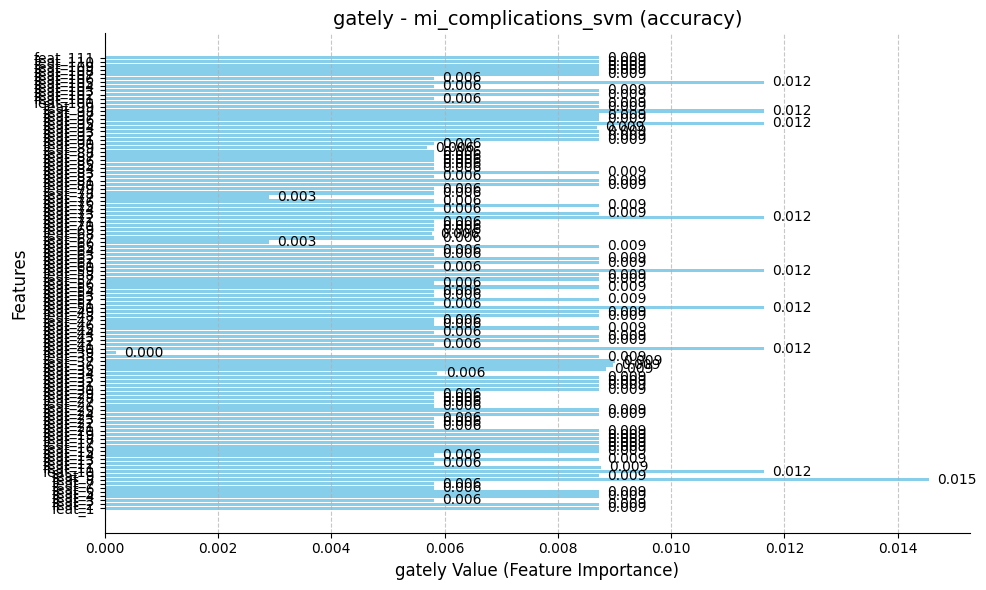

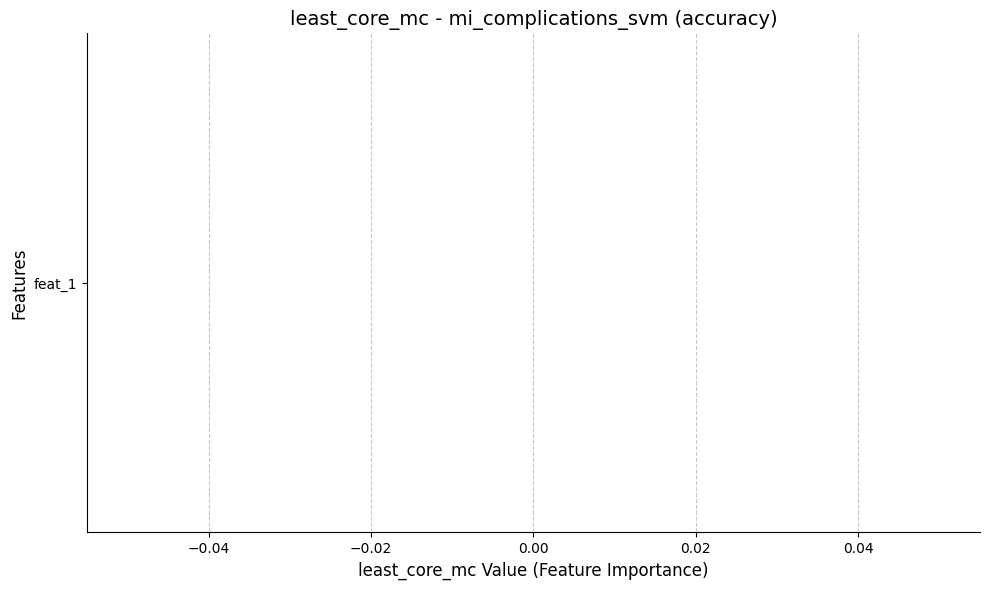

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
import sys

from scipy.stats import spearmanr, pearsonr
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error, r2_score, mean_absolute_error

# Add project root to sys.path (robust)
from pathlib import Path as _Path
HERE = _Path.cwd().resolve()
root = None
for p in [HERE] + list(HERE.parents):
    if (p / "gt_concepts").is_dir():
        root = p
        break
if root is None:
    raise RuntimeError(f"Could not find project root containing 'gt_concepts' from {HERE}")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
print("Project root added to sys.path:", root)

# Project imports
from models.train_model import get_model
from utils.plotting import plot_single_valuation

from gt_concepts.gately_point import exact_gately_value
from gt_concepts.least_core import montecarlo_least_core
from gt_concepts.shapley import montecarlo_shapley_value

# Logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Config
DATASETS = ["mi_complications"]
MODEL_NAMES = ["svm", "logistic", "random_forest"]
SCORING = "accuracy"
RANDOM_STATE = 42

BASE_OUTPUT_DIR = Path("./output/feature_valuation_uci_paper_eval_multi_master_fast")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Curve settings (masking, no retrain -> can afford higher)
CURVE_STEPS = 50

# Robustness settings (masking-based, fast)
NOISE_LEVEL = 0.05
BOOTSTRAP_ROUNDS = 10

# Attribution budgets (THIS is what prevents multi-day runs)
SHAPLEY_MC_ITERS = 50          # was 100/1000 -> too slow for n=111 with retraining
LEAST_CORE_MC_ITERS = 120      # was 300/3000 -> too slow
LEAST_CORE_EPSILON = 1e-6

LEAST_CORE_SOLVER_OPTS = {
    "solver": "SCS",
    "max_iters": 15000,
    "eps": 1e-5,
    "verbose": False
}

# Optional: evaluate only top-K features for deletion/insertion
TOPK_FOR_CURVES = None  # e.g. 50 to speed even more; None uses all features

# Dataset loaders
def load_mi_complications(binary_let_is=True):
    path = "../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    let_is = df.iloc[:, 123].astype(int).values
    y = (let_is != 0).astype(int) if binary_let_is else let_is

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_lung_cancer():
    path = "../datasets/lung-cancer.data"
    df = pd.read_csv(path, header=None, na_values="?")

    y = df.iloc[:, 0].astype(int).values
    X_df = df.iloc[:, 1:]
    feature_names = [f"attr_{i}" for i in range(1, X_df.shape[1] + 1)]

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_dataset(name: str):
    if name == "mi_complications":
        return load_mi_complications(binary_let_is=True)
    elif name == "lung_cancer":
        return load_lung_cancer()
    else:
        raise ValueError(f"Unknown dataset name: {name}")

# Utility (retraining) for game-based attributions
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)


class Utility:
    """
    v(S): train model on features S, evaluate on test.
    Heavy but used only for computing attributions & LOO impacts.
    """
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer,
                 feature_names=None, random_state=42):
        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]

        if len(key) == 0:
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = score
            return score

        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = score
        return score


def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")

# LOO impacts (still retrain; n=111 -> manageable)
def loo_impacts(utility: Utility):
    n = len(utility.data)
    all_set = set(range(n))
    vN = utility(list(all_set))
    impacts = np.zeros(n)
    for i in range(n):
        vN_minus_i = utility(list(all_set - {i}))
        impacts[i] = vN - vN_minus_i
    return vN, impacts

# FAST deletion/insertion using masking (NO retrain)
def train_full_model(X_train, y_train, X_test, y_test, model_name, random_state):
    model = get_model(model_name, random_state)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return model, y_pred


def score_model(model, X_test, y_test, scorer):
    y_pred = model.predict(X_test)
    return float(scorer(y_test, y_pred))


def masking_curve_auc(model, X_ref, X_test, y_test, order, steps, mode, scorer):
    """
    mode = 'deletion' or 'insertion'
    deletion: start from X_test, replace removed features with baseline X_ref (mean)
    insertion: start from baseline, add features from X_test
    """
    n = X_test.shape[1]
    if TOPK_FOR_CURVES is not None:
        order = order[:TOPK_FOR_CURVES]
        n = len(order)

    fracs = np.linspace(0, 1, steps)
    scores = []

    baseline = X_ref.copy()

    for f in fracs:
        k = int(round(f * n))
        chosen = set(order[:k].tolist())

        if mode == "deletion":
            X_masked = X_test.copy()
            # remove chosen => set to baseline
            for j in chosen:
                X_masked[:, j] = baseline[j]
        elif mode == "insertion":
            X_masked = np.tile(baseline, (X_test.shape[0], 1))
            # insert chosen => copy real values
            for j in chosen:
                X_masked[:, j] = X_test[:, j]
        else:
            raise ValueError("mode must be deletion or insertion")

        scores.append(score_model(model, X_masked, y_test, scorer))

    return float(np.trapezoid(np.array(scores), fracs))


def deletion_auc_drop_masked(model, baseline_vec, X_test, y_test, attribution, steps, scorer, rng_seed=42):
    order_attr = np.argsort(-np.abs(attribution))
    rng = np.random.default_rng(rng_seed)
    order_rand = rng.permutation(len(attribution))

    auc_attr = masking_curve_auc(model, baseline_vec, X_test, y_test, order_attr, steps, "deletion", scorer)
    auc_rand = masking_curve_auc(model, baseline_vec, X_test, y_test, order_rand, steps, "deletion", scorer)
    return float(auc_rand - auc_attr)


def insertion_auc_gain_masked(model, baseline_vec, X_test, y_test, attribution, steps, scorer, rng_seed=42):
    order_attr = np.argsort(-np.abs(attribution))
    rng = np.random.default_rng(rng_seed)
    order_rand = rng.permutation(len(attribution))

    auc_attr = masking_curve_auc(model, baseline_vec, X_test, y_test, order_attr, steps, "insertion", scorer)
    auc_rand = masking_curve_auc(model, baseline_vec, X_test, y_test, order_rand, steps, "insertion", scorer)
    return float(auc_attr - auc_rand)

# Robustness (fast): compare attributions under noisy/bootstrap TRAIN,
# but faithfulness curves remain masked on TEST -> fast.
def cosine(a, b):
    return float(np.dot(a, b) / ((np.linalg.norm(a) * np.linalg.norm(b)) + 1e-12))

# Attribution methods (same as before)
def gately_method_fn(utility: Utility) -> np.ndarray:
    res = exact_gately_value(utility, options=None, progress=False)
    return np.array(res.values, dtype=float)


def least_core_mc_method_fn(utility: Utility) -> np.ndarray:
    res = montecarlo_least_core(
        utility,
        n_iterations=LEAST_CORE_MC_ITERS,
        epsilon=LEAST_CORE_EPSILON,
        options=LEAST_CORE_SOLVER_OPTS,
        progress=False
    )
    return np.array(res.values, dtype=float)


def shapley_mc_method_fn(utility: Utility) -> np.ndarray:
    res = montecarlo_shapley_value(
        utility,
        n_iterations=SHAPLEY_MC_ITERS,
        options=None,
        progress=False
    )
    return np.array(res.values, dtype=float)


ATTRIBUTION_METHODS = {
    "gately": gately_method_fn,
    "least_core_mc": least_core_mc_method_fn,
    "mc_shapley": shapley_mc_method_fn,
}

# Ranking + summaries (paper steps 2 & 3)
def rank_methods(metric_df: pd.DataFrame, higher_is_better_cols):
    rank_df = pd.DataFrame(index=metric_df.index)
    for col in metric_df.columns:
        higher = col in higher_is_better_cols
        rank_df[col] = metric_df[col].rank(ascending=not higher, method="average")
    return rank_df


def rank_summary(rank_df: pd.DataFrame):
    return pd.DataFrame({
        "mean_rank_mu_hat": rank_df.mean(axis=1),
        "std_rank_sigma_hat": rank_df.std(axis=1, ddof=0)
    }).sort_values("mean_rank_mu_hat")

# Main (MASTER CSV aggregation)
def main():
    scorer = get_scorer(SCORING)

    master_rows_faith = []
    master_rows_rob = []
    master_rows_faith_rank = []
    master_rows_rob_rank = []
    master_rows_faith_summary = []
    master_rows_rob_summary = []

    for dataset_name in DATASETS:
        X_train, X_test, y_train, y_test, feature_names = load_dataset(dataset_name)

        for model_name in MODEL_NAMES:
            logger.info("\n" + "=" * 70)
            logger.info(f"DATASET: {dataset_name} | MODEL: {model_name}")
            logger.info("=" * 70)

            OUTPUT_DIR = BASE_OUTPUT_DIR / f"{dataset_name}_{model_name}_results"
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

            # Utility used for attributions and LOO impacts (retraining)
            utility = Utility(
                X_train, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            # Train full model once for masking curves
            full_model = get_model(model_name, RANDOM_STATE)
            full_model.fit(X_train, y_train)

            baseline_vec = X_train.mean(axis=0)

            vN, impacts = loo_impacts(utility)
            logger.info(f"  v(N) with all features ({SCORING}) = {vN:.4f}")

            # Compute attributions
            attributions = {}
            for mname, mfn in ATTRIBUTION_METHODS.items():
                logger.info(f"Computing attributions: {mname}")
                phi = mfn(utility)
                attributions[mname] = phi

                df_vals = pd.DataFrame({"method": mname, "feature": feature_names, "value": phi})
                df_vals.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_feature_valuations_{mname}.csv", index=False)

                try:
                    plot_single_valuation(
                        phi, feature_names,
                        method_name=mname,
                        title=f"{mname} - {dataset_name}_{model_name} ({SCORING})",
                        output_path=OUTPUT_DIR / f"{dataset_name}_{model_name}_{mname}.png"
                    )
                except Exception as e:
                    logger.warning(f"Plot failed for {mname}: {e}")

            # Step 1: Faithfulness metrics (LOO retrain + masked curves)
            faith_rows = []
            for mname, phi in attributions.items():
                sp, sp_p = spearmanr(phi, impacts)
                pe, pe_p = pearsonr(phi, impacts)

                del_drop = deletion_auc_drop_masked(
                    full_model, baseline_vec, X_test, y_test, phi,
                    steps=CURVE_STEPS, scorer=scorer, rng_seed=RANDOM_STATE
                )
                ins_gain = insertion_auc_gain_masked(
                    full_model, baseline_vec, X_test, y_test, phi,
                    steps=CURVE_STEPS, scorer=scorer, rng_seed=RANDOM_STATE
                )

                row = {
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": mname,
                    "loo_spearman": float(sp),
                    "loo_pearson": float(pe),
                    "deletion_auc_drop": float(del_drop),
                    "insertion_auc_gain": float(ins_gain),
                    "p_spearman": float(sp_p),
                    "p_pearson": float(pe_p),
                    "vN": float(vN),
                }
                faith_rows.append(row)
                master_rows_faith.append(row)

            faith_df = pd.DataFrame(faith_rows).set_index("method")
            faith_df.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_faithfulness_metrics_raw.csv")
            logger.info("\nFaithfulness metrics (raw):\n" + faith_df.to_string())

            # Step 1: Robustness metrics (cosine between attribution vectors)
            rob_rows = []
            for mname, mfn in ATTRIBUTION_METHODS.items():
                phi0 = attributions[mname]

                # noise on training
                noise = np.random.normal(0, NOISE_LEVEL * X_train.std(axis=0), X_train.shape)
                util_noisy = Utility(
                    X_train + noise, y_train, X_test, y_test,
                    model_name=model_name,
                    scorer=scorer,
                    feature_names=feature_names,
                    random_state=RANDOM_STATE + 11
                )
                phi_noise = mfn(util_noisy)
                noise_cos = cosine(phi0, phi_noise)

                # bootstrap stability
                rng = np.random.default_rng(RANDOM_STATE)
                n = X_train.shape[0]
                cos_list = []
                for r in range(BOOTSTRAP_ROUNDS):
                    idx = rng.integers(0, n, size=n)
                    util_b = Utility(
                        X_train[idx], y_train[idx], X_test, y_test,
                        model_name=model_name,
                        scorer=scorer,
                        feature_names=feature_names,
                        random_state=RANDOM_STATE + 1000 + r
                    )
                    phi_b = mfn(util_b)
                    cos_list.append(cosine(phi0, phi_b))

                row = {
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": mname,
                    "noise_cosine": float(noise_cos),
                    "bootstrap_cosine": float(np.mean(cos_list)),
                }
                rob_rows.append(row)
                master_rows_rob.append(row)

            rob_df = pd.DataFrame(rob_rows).set_index("method")
            rob_df.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_robustness_metrics_raw.csv")
            logger.info("\nRobustness metrics (raw):\n" + rob_df.to_string())

            # Step 2: Rank per metric
            faith_metric_cols = ["loo_spearman", "loo_pearson", "deletion_auc_drop", "insertion_auc_gain"]
            rob_metric_cols = ["noise_cosine", "bootstrap_cosine"]

            faith_rank = rank_methods(faith_df[faith_metric_cols], higher_is_better_cols=set(faith_metric_cols))
            rob_rank = rank_methods(rob_df[rob_metric_cols], higher_is_better_cols=set(rob_metric_cols))

            faith_rank.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_faithfulness_ranks.csv")
            rob_rank.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_robustness_ranks.csv")

            for method in faith_rank.index:
                r = {"dataset": dataset_name, "model": model_name, "method": method}
                r.update({f"rank_{c}": float(faith_rank.loc[method, c]) for c in faith_metric_cols})
                master_rows_faith_rank.append(r)

            for method in rob_rank.index:
                r = {"dataset": dataset_name, "model": model_name, "method": method}
                r.update({f"rank_{c}": float(rob_rank.loc[method, c]) for c in rob_metric_cols})
                master_rows_rob_rank.append(r)

            # Step 3: Mean rank μ̂ and disagreement σ̂
            faith_summary = rank_summary(faith_rank)
            rob_summary = rank_summary(rob_rank)

            faith_summary.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_faithfulness_rank_summary.csv")
            rob_summary.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_robustness_rank_summary.csv")

            logger.info("\nFaithfulness rank summary (μ̂, σ̂):\n" + faith_summary.to_string())
            logger.info("\nRobustness rank summary (μ̂, σ̂):\n" + rob_summary.to_string())

            for method in faith_summary.index:
                master_rows_faith_summary.append({
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": method,
                    "faith_mean_rank_mu_hat": float(faith_summary.loc[method, "mean_rank_mu_hat"]),
                    "faith_std_rank_sigma_hat": float(faith_summary.loc[method, "std_rank_sigma_hat"]),
                })
            for method in rob_summary.index:
                master_rows_rob_summary.append({
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": method,
                    "rob_mean_rank_mu_hat": float(rob_summary.loc[method, "mean_rank_mu_hat"]),
                    "rob_std_rank_sigma_hat": float(rob_summary.loc[method, "std_rank_sigma_hat"]),
                })

            logger.info(f"\nSaved per-run outputs to: {OUTPUT_DIR}")
            logger.info("=" * 70)

    # MASTER CSVs
    master_faith = pd.DataFrame(master_rows_faith)
    master_rob = pd.DataFrame(master_rows_rob)
    master_faith_rank = pd.DataFrame(master_rows_faith_rank)
    master_rob_rank = pd.DataFrame(master_rows_rob_rank)
    master_faith_summary = pd.DataFrame(master_rows_faith_summary)
    master_rob_summary = pd.DataFrame(master_rows_rob_summary)

    paper_master = master_faith.merge(master_rob, on=["dataset", "model", "method"], how="outer")
    paper_master = paper_master.merge(master_faith_summary, on=["dataset", "model", "method"], how="outer")
    paper_master = paper_master.merge(master_rob_summary, on=["dataset", "model", "method"], how="outer")

    master_faith_path = BASE_OUTPUT_DIR / "MASTER_faithfulness_raw.csv"
    master_rob_path = BASE_OUTPUT_DIR / "MASTER_robustness_raw.csv"
    master_faith_rank_path = BASE_OUTPUT_DIR / "MASTER_faithfulness_ranks.csv"
    master_rob_rank_path = BASE_OUTPUT_DIR / "MASTER_robustness_ranks.csv"
    paper_master_path = BASE_OUTPUT_DIR / "MASTER_paper_table.csv"

    master_faith.to_csv(master_faith_path, index=False)
    master_rob.to_csv(master_rob_path, index=False)
    master_faith_rank.to_csv(master_faith_rank_path, index=False)
    master_rob_rank.to_csv(master_rob_rank_path, index=False)
    paper_master.to_csv(paper_master_path, index=False)

    logger.info("\nMASTER CSVs saved:")
    logger.info(f"  {master_faith_path}")
    logger.info(f"  {master_rob_path}")
    logger.info(f"  {master_faith_rank_path}")
    logger.info(f"  {master_rob_rank_path}")
    logger.info(f"  {paper_master_path}")


if __name__ == "__main__":
    main()

In [ ]:
"""
Corrected version of your script (as discussed):

Key fixes (paper-aligned, avoids OOD artifacts):
1) Masking baseline is NOT median/mean anymore.
   - Deletion: replace removed features by column-wise samples from TRAIN (on-manifold-ish).
   - Insertion: start from a sampled TRAIN row, then insert important features from X_test.

2) Curve scoring is NOT accuracy anymore (too step-like).
   - Uses negative log-loss when predict_proba exists,
   - else uses signed margin (decision_function) for SVM-like models.

3) Faithfulness-corr uses the same perturbation protocol & scoring signal (proba/margin),
   and correlates subset mean |phi| with actual average drop.

Everything else (your retraining game, LOO, robustness, attributions, ranks, master CSVs)
is kept compatible.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
import sys
import warnings
from typing import Dict, Optional, Tuple

from scipy.stats import spearmanr, pearsonr
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, mean_squared_error, r2_score, mean_absolute_error,
    log_loss
)

# Add project root to sys.path (robust)
from pathlib import Path as _Path

HERE = _Path.cwd().resolve()
root = None
for p in [HERE] + list(HERE.parents):
    if (p / "gt_concepts").is_dir():
        root = p
        break
if root is None:
    raise RuntimeError(f"Could not find project root containing 'gt_concepts' from {HERE}")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
print("Project root added to sys.path:", root)

# Project imports
from models.train_model import get_model
from utils.plotting import plot_single_valuation

from gt_concepts.gately_point import exact_gately_value
from gt_concepts.least_core import montecarlo_least_core
from gt_concepts.shapley import montecarlo_shapley_value

# Logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Config
DATASETS = ["mi_complications"]  # add "lung_cancer" if desired
MODEL_NAMES = ["svm"]
SCORING = "accuracy"
RANDOM_STATE = 42

BASE_OUTPUT_DIR = Path("./output/feature_valuation_uci_paper_eval_multi_master_corrected_v2_onmanifold")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Curve settings (masking-based => can be higher without huge retrain cost)
CURVE_STEPS = 10

# Robustness settings
NOISE_LEVEL = 0.05
BOOTSTRAP_ROUNDS = 10

# Shapley settings
SHAPLEY_MC_ITERS = 100

# Least-core settings
LEAST_CORE_MC_ITERS = 300
LEAST_CORE_EPSILON = 1e-6

LEAST_CORE_SOLVER_OPTS = {
    "solver": "SCS",
    "max_iters": 25000,
    "eps": 1e-6,
    "verbose": False
}

# Faithfulness-corr settings
FC_N_TESTS = 10
FC_SUBSET_SIZE = 20

# Masking perturbation sampling
PERTURB_N_BASELINES = 2  # number of baseline samples per step (MC averaging)
PERTURB_BATCH = 1024      # batch size for model calls to reduce RAM peaks

# Dataset loaders
def load_lung_cancer():
    path = "../datasets/lung-cancer.data"
    df = pd.read_csv(path, header=None, na_values="?")

    y = df.iloc[:, 0].astype(int).values
    X_df = df.iloc[:, 1:]
    feature_names = [f"attr_{i}" for i in range(1, X_df.shape[1] + 1)]

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_mi_complications(binary_let_is=True):
    path = "../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    let_is = df.iloc[:, 123].astype(int).values
    y = (let_is != 0).astype(int) if binary_let_is else let_is

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_dataset(name: str):
    if name == "lung_cancer":
        return load_lung_cancer()
    elif name == "mi_complications":
        return load_mi_complications(binary_let_is=True)
    else:
        raise ValueError(f"Unknown dataset name: {name}")

# Utility + scorer (retraining game)
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)


class Utility:
    """
    v(S): train model on features S, evaluate on test.
    Includes caching for speed.
    """
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer,
                 feature_names=None, random_state=42):
        self.X_train = np.asarray(X_train)
        self.y_train = np.asarray(y_train)
        self.X_test = np.asarray(X_test)
        self.y_test = np.asarray(y_test)
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(self.X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]

        if len(key) == 0:
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = float(score)
            return float(score)

        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = float(score)
        return float(score)


def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")

# LOO impacts (retraining paradigm)
def loo_impacts(utility: Utility):
    n = len(utility.data)
    all_set = set(range(n))
    vN = utility(list(all_set))
    impacts = np.zeros(n, dtype=float)
    for i in range(n):
        vN_minus_i = utility(list(all_set - {i}))
        impacts[i] = vN - vN_minus_i
    return float(vN), impacts

# Robustness helpers
def cosine(a, b):
    return float(np.dot(a, b) / ((np.linalg.norm(a) * np.linalg.norm(b)) + 1e-12))


def noise_stability_cosine(base_utility: Utility, method_fn, noise_level: float = 0.05):
    phi0 = method_fn(base_utility)

    X_train = base_utility.X_train
    noise = np.random.normal(0, noise_level * X_train.std(axis=0), X_train.shape)
    X_noisy = X_train + noise

    util_noisy = Utility(
        X_noisy, base_utility.y_train, base_utility.X_test, base_utility.y_test,
        model_name=base_utility.model_name,
        scorer=base_utility.scorer,
        feature_names=base_utility.data.data_names,
        random_state=base_utility.random_state + 11
    )
    phi_noisy = method_fn(util_noisy)
    return cosine(phi0, phi_noisy)


def bootstrap_stability_cosine(base_utility: Utility, method_fn, rounds: int = 10):
    X_train = base_utility.X_train
    y_train = base_utility.y_train
    X_test = base_utility.X_test
    y_test = base_utility.y_test

    phi0 = method_fn(base_utility)

    rng = np.random.default_rng(base_utility.random_state)
    n = X_train.shape[0]
    cos_list = []
    for r in range(rounds):
        idx = rng.integers(0, n, size=n)
        Xb = X_train[idx]
        yb = y_train[idx]

        util_b = Utility(
            Xb, yb, X_test, y_test,
            model_name=base_utility.model_name,
            scorer=base_utility.scorer,
            feature_names=base_utility.data.data_names,
            random_state=base_utility.random_state + 1000 + r
        )
        phi_b = method_fn(util_b)
        cos_list.append(cosine(phi0, phi_b))

    return float(np.mean(cos_list))

# Attribution methods
def gately_method_fn(utility: Utility) -> np.ndarray:
    res = exact_gately_value(utility, options=None, progress=False)
    return np.array(res.values, dtype=float)


def least_core_mc_method_fn(utility: Utility) -> np.ndarray:
    res = montecarlo_least_core(
        utility,
        n_iterations=LEAST_CORE_MC_ITERS,
        epsilon=LEAST_CORE_EPSILON,
        options=LEAST_CORE_SOLVER_OPTS,
        progress=False
    )
    return np.array(res.values, dtype=float)


def shapley_mc_method_fn(utility: Utility) -> np.ndarray:
    res = montecarlo_shapley_value(
        utility,
        n_iterations=SHAPLEY_MC_ITERS,
        options=None,
        progress=False
    )
    return np.array(res.values, dtype=float)


ATTRIBUTION_METHODS = {
    "gately": gately_method_fn,
    "least_core_mc": least_core_mc_method_fn,
    "mc_shapley": shapley_mc_method_fn,
}

class OnManifoldFaithfulnessEvaluator:
    """
    Masking-based metrics with TRAIN-sampling baselines + smooth score signal.

    - Deletion: for removed features, replace by values sampled from TRAIN columns
               (MC over several sampled baselines).
    - Insertion: start from a sampled TRAIN row and insert chosen features from X_test.

    Score signal:
    - If predict_proba available: use negative log-loss (higher is better).
    - Else decision_function: use signed margin mean (higher is better).
    - Else fallback to accuracy (coarse, but works).

    This avoids the "negative insertion AUC everywhere" artifact from median masking + accuracy.
    """

    def __init__(self, model, X_train, X_test, y_test, rng_seed: int = 42):
        if model is None:
            raise ValueError("model must be trained.")
        self.model = model
        self.X_train = np.asarray(X_train)
        self.X_test = np.asarray(X_test)
        self.y_test = np.asarray(y_test)
        self.rng = np.random.default_rng(rng_seed)

        self._has_proba = hasattr(model, "predict_proba") and callable(getattr(model, "predict_proba"))
        self._has_decision = hasattr(model, "decision_function") and callable(getattr(model, "decision_function"))

        # For log-loss, we need stable class list
        self._classes = getattr(model, "classes_", None)

        # Cache original signal for faithfulness_corr drops
        self._orig_signal = self._signal(self.X_test)  # vector per-sample

    def _signal(self, X: np.ndarray) -> np.ndarray:
        """
        Batch-safe per-row "confidence" signal where higher is better.

        IMPORTANT:
        X may be a stacked batch containing multiple copies of the test set:
        X.shape[0] can be B * n_test (or any chunk size during batching).
        So we repeat y_test (and its mapped class indices) to match X rows.
        """
        eps = 1e-12
        n = X.shape[0]
        n_test = self.y_test.shape[0]

        # Repeat y_test to match batch length n
        reps = int(np.ceil(n / n_test))
        y_rep = np.tile(self.y_test, reps)[:n]

        if self._has_proba:
            proba = self.model.predict_proba(X)

            # Map labels -> class indices robustly
            if self._classes is None:
                cls_idx = y_rep.astype(int)
            else:
                # cache mapping once
                if not hasattr(self, "_cls_to_i"):
                    self._cls_to_i = {c: i for i, c in enumerate(self._classes)}
                cls_idx = np.array([self._cls_to_i[y] for y in y_rep], dtype=int)

            p_true = proba[np.arange(n), cls_idx]
            return np.log(p_true + eps)

        if self._has_decision:
            dec = self.model.decision_function(X)
            # binary: (n,), multiclass: (n,C)
            if dec.ndim == 1:
                if self._classes is None or len(self._classes) != 2:
                    sign = np.where(y_rep == 1, 1.0, -1.0)
                else:
                    pos = self._classes[1]
                    sign = np.where(y_rep == pos, 1.0, -1.0)
                return sign * dec
            else:
                if self._classes is None:
                    cls_idx = y_rep.astype(int)
                else:
                    if not hasattr(self, "_cls_to_i"):
                        self._cls_to_i = {c: i for i, c in enumerate(self._classes)}
                    cls_idx = np.array([self._cls_to_i[y] for y in y_rep], dtype=int)
                return dec[np.arange(n), cls_idx]

        y_pred = self.model.predict(X)
        return (y_pred == y_rep).astype(float)


    def _aggregate_score(self, signal_vec: np.ndarray) -> float:
        """Aggregate per-sample signal to a scalar score."""
        return float(np.mean(signal_vec))

    def _sample_train_rows(self, m: int) -> np.ndarray:
        """Sample m rows from training (with replacement)."""
        idx = self.rng.integers(0, self.X_train.shape[0], size=m)
        return self.X_train[idx]

    def _sample_train_columns(self, m: int) -> np.ndarray:
        """
        Sample m baseline rows by independent column sampling from TRAIN.
        This keeps marginal distributions and reduces extreme OOD.
        """
        n_train, d = self.X_train.shape
        out = np.empty((m, d), dtype=self.X_train.dtype)
        for j in range(d):
            idx = self.rng.integers(0, n_train, size=m)
            out[:, j] = self.X_train[idx, j]
        return out

    def _make_deletion_batch(self, cols_remove: np.ndarray, n_baselines: int) -> np.ndarray:
        """
        Returns stacked batch of masked test sets:
          shape = (n_baselines * n_test, d)
        Each baseline is a sampled row (column-sampled) used to fill removed cols.
        """
        n_test, d = self.X_test.shape
        # baseline rows for filling removed columns
        base_rows = self._sample_train_columns(n_baselines)

        X_stack = np.repeat(self.X_test[None, :, :], n_baselines, axis=0)
        X_stack[:, :, cols_remove] = base_rows[:, None, cols_remove]       # fill removed cols
        return X_stack.reshape(n_baselines * n_test, d)

    def _make_insertion_batch(self, cols_keep: np.ndarray, n_baselines: int) -> np.ndarray:
        """
        Start from sampled TRAIN rows (row baselines), insert cols_keep from X_test.
        Stacked batch shape = (B*n_test, d)
        """
        n_test, d = self.X_test.shape
        base_rows = self._sample_train_rows(n_baselines)

        # For each baseline b and each test sample i: start = base_rows[b], then insert cols_keep from X_test[i]
        X_base = np.repeat(base_rows[:, None, :], n_test, axis=1)
        X_base[:, :, cols_keep] = self.X_test[None, :, cols_keep]
        return X_base.reshape(n_baselines * n_test, d)

    def _batched_score(self, X_big: np.ndarray, n_test: int, n_baselines: int) -> float:
        """
        Compute mean score over baselines:
        - Predict on X_big in chunks
        - Convert to signal
        - Reshape to (B, n_test) and average over B and samples
        """
        # compute signal for whole big batch
        sig = []
        for i in range(0, X_big.shape[0], PERTURB_BATCH):
            sig.append(self._signal(X_big[i:i + PERTURB_BATCH]))
        sig = np.concatenate(sig, axis=0)
        sig = sig.reshape(n_baselines, n_test)
        return float(np.mean(sig))  # average over baselines and test samples

    def masking_curve_auc(self, order: np.ndarray, steps: int, mode: str,
                          n_baselines: int = 8) -> float:
        fracs = np.linspace(0, 1, steps)
        scores = []
        d = len(order)
        n_test = self.X_test.shape[0]

        for f in fracs:
            k = int(round(f * d))
            if mode == "deletion":
                cols = order[:k] if k > 0 else np.array([], dtype=int)
                if cols.size == 0:
                    score = self._aggregate_score(self._orig_signal)
                else:
                    X_big = self._make_deletion_batch(cols, n_baselines)
                    score = self._batched_score(X_big, n_test, n_baselines)
            elif mode == "insertion":
                cols = order[:k] if k > 0 else np.array([], dtype=int)
                if cols.size == 0:
                    # insertion start baseline => expected "baseline score"
                    X_big = self._make_insertion_batch(np.array([], dtype=int), n_baselines)
                    score = self._batched_score(X_big, n_test, n_baselines)
                else:
                    X_big = self._make_insertion_batch(cols, n_baselines)
                    score = self._batched_score(X_big, n_test, n_baselines)
            else:
                raise ValueError("mode must be 'deletion' or 'insertion'")

            scores.append(score)

        return float(np.trapezoid(np.array(scores), fracs))

    def deletion_auc_drop(self, attribution: np.ndarray, steps: int,
                          n_baselines: int = 8, rng_seed: int = 42) -> float:
        order_attr = np.argsort(-np.abs(attribution))
        order_rand = np.random.default_rng(rng_seed).permutation(len(attribution))
        auc_attr = self.masking_curve_auc(order_attr, steps, "deletion", n_baselines=n_baselines)
        auc_rand = self.masking_curve_auc(order_rand, steps, "deletion", n_baselines=n_baselines)
        return float(auc_rand - auc_attr)

    def insertion_auc_gain(self, attribution: np.ndarray, steps: int,
                           n_baselines: int = 8, rng_seed: int = 42) -> float:
        order_attr = np.argsort(-np.abs(attribution))
        order_rand = np.random.default_rng(rng_seed).permutation(len(attribution))
        auc_attr = self.masking_curve_auc(order_attr, steps, "insertion", n_baselines=n_baselines)
        auc_rand = self.masking_curve_auc(order_rand, steps, "insertion", n_baselines=n_baselines)
        return float(auc_attr - auc_rand)

    def faithfulness_corr(self, attribution: np.ndarray, n_tests: int = 100,
                          subset_size: int = 20, n_baselines: int = 8) -> float:
        """
        Correlate:
          x = mean |phi| over random subset
          y = mean signal drop when masking that subset (deletion protocol)
        """
        abs_attr = np.abs(attribution)
        d = len(attribution)
        k = min(int(subset_size), max(1, d // 2))
        rng = np.random.default_rng(42)

        x = np.empty(n_tests, dtype=float)
        y = np.empty(n_tests, dtype=float)

        base_score = self._aggregate_score(self._orig_signal)
        n_test = self.X_test.shape[0]

        for t in range(n_tests):
            subset = rng.choice(d, size=k, replace=False)
            x[t] = float(abs_attr[subset].mean())

            X_big = self._make_deletion_batch(subset, n_baselines)
            score_mask = self._batched_score(X_big, n_test, n_baselines)
            y[t] = float(base_score - score_mask)  # drop

        corr, _ = pearsonr(x, y)
        return float(corr)

    def sufficiency_multi(self, attribution: np.ndarray, thresholds=(0.8, 0.9, 0.95),
                          n_baselines: int = 8) -> Dict[str, float]:
        """
        Proportion of features needed so insertion score reaches thr * full_score.
        Uses insertion protocol + smooth signal.
        """
        abs_attr = np.abs(attribution)
        order = np.argsort(-abs_attr)
        d = len(order)

        full_score = self._aggregate_score(self._orig_signal)
        out: Dict[str, float] = {}

        n_test = self.X_test.shape[0]

        for thr in thresholds:
            target = thr * full_score
            found = False
            for k in range(1, d + 1):
                cols = order[:k]
                X_big = self._make_insertion_batch(cols, n_baselines)
                score_k = self._batched_score(X_big, n_test, n_baselines)
                if score_k >= target:
                    out[f"sufficiency_{int(thr*100)}"] = float(k / d)
                    found = True
                    break
            if not found:
                out[f"sufficiency_{int(thr*100)}"] = 1.0

        return out

    def evaluate_masking_metrics(self, attribution: np.ndarray, steps: int,
                                n_baselines: int = 8) -> Dict[str, float]:
        res: Dict[str, float] = {}
        res["deletion_auc_drop"] = self.deletion_auc_drop(attribution, steps, n_baselines=n_baselines, rng_seed=42)
        res["insertion_auc_gain"] = self.insertion_auc_gain(attribution, steps, n_baselines=n_baselines, rng_seed=42)
        res["faithfulness_corr"] = self.faithfulness_corr(attribution, n_tests=FC_N_TESTS,
                                                          subset_size=FC_SUBSET_SIZE, n_baselines=n_baselines)
        res.update(self.sufficiency_multi(attribution, thresholds=(0.8, 0.9, 0.95), n_baselines=n_baselines))
        return res

# Ranking + summaries (exclude metadata)
def rank_methods(metric_df: pd.DataFrame, higher_is_better_cols):
    rank_df = pd.DataFrame(index=metric_df.index)
    for col in metric_df.columns:
        higher = col in higher_is_better_cols
        rank_df[col] = metric_df[col].rank(ascending=not higher, method="average")
    return rank_df


def rank_summary(rank_df: pd.DataFrame):
    return pd.DataFrame({
        "mean_rank_mu_hat": rank_df.mean(axis=1),
        "std_rank_sigma_hat": rank_df.std(axis=1, ddof=0)
    }).sort_values("mean_rank_mu_hat")

# Main
def main():
    scorer = get_scorer(SCORING)

    master_rows_faith = []
    master_rows_rob = []
    master_rows_faith_rank = []
    master_rows_rob_rank = []
    master_rows_faith_summary = []
    master_rows_rob_summary = []

    for dataset_name in DATASETS:
        X_train, X_test, y_train, y_test, feature_names = load_dataset(dataset_name)

        for model_name in MODEL_NAMES:
            logger.info("\n" + "=" * 70)
            logger.info(f"DATASET: {dataset_name} | MODEL: {model_name}")
            logger.info("=" * 70)

            OUTPUT_DIR = BASE_OUTPUT_DIR / f"{dataset_name}_{model_name}_results"
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

            # retraining-game utility
            utility = Utility(
                X_train, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            # Train full model ONCE for masking metrics
            full_model = get_model(model_name, RANDOM_STATE)
            full_model.fit(X_train, y_train)

            evaluator = OnManifoldFaithfulnessEvaluator(
                full_model, X_train, X_test, y_test, rng_seed=RANDOM_STATE
            )

            vN, impacts = loo_impacts(utility)
            logger.info(f"  v(N) with all features ({SCORING}) = {vN:.4f}")

            # Compute attributions (retraining game)
            attributions = {}
            for mname, mfn in ATTRIBUTION_METHODS.items():
                logger.info(f"Computing attributions: {mname}")
                phi = mfn(utility)
                attributions[mname] = phi

                df_vals = pd.DataFrame({"method": mname, "feature": feature_names, "value": phi})
                df_vals.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_feature_valuations_{mname}.csv", index=False)

                try:
                    plot_single_valuation(
                        phi, feature_names,
                        method_name=mname,
                        title=f"{mname} - {dataset_name}_{model_name} ({SCORING})",
                        output_path=OUTPUT_DIR / f"{dataset_name}_{model_name}_{mname}.png"
                    )
                except Exception as e:
                    logger.warning(f"Plot failed for {mname}: {e}")

            # Faithfulness metrics (MULTI-METRIC, corrected perturbations)
            faith_rows = []
            for mname, phi in attributions.items():
                # LOO correlations (retraining paradigm)
                sp, p_sp = spearmanr(phi, impacts)
                pe, p_pe = pearsonr(phi, impacts)

                mask_metrics = evaluator.evaluate_masking_metrics(
                    phi, steps=CURVE_STEPS, n_baselines=PERTURB_N_BASELINES
                )

                row = {
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": mname,
                    "loo_spearman": float(sp),
                    "loo_pearson": float(pe),
                    "_p_spearman": float(p_sp),
                    "_p_pearson": float(p_pe),
                    "vN": float(vN),
                    **mask_metrics,
                }
                faith_rows.append(row)
                master_rows_faith.append(row)

            faith_df = pd.DataFrame(faith_rows).set_index("method")
            faith_df.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_faithfulness_metrics_raw.csv")
            logger.info("\nFaithfulness metrics (raw):\n" + faith_df.to_string())

            rob_rows = []
            for mname, mfn in ATTRIBUTION_METHODS.items():
                noise_cos = noise_stability_cosine(utility, mfn, noise_level=NOISE_LEVEL)
                boot_cos = bootstrap_stability_cosine(utility, mfn, rounds=BOOTSTRAP_ROUNDS)
                row = {
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": mname,
                    "noise_cosine": float(noise_cos),
                    "bootstrap_cosine": float(boot_cos),
                }
                rob_rows.append(row)
                master_rows_rob.append(row)

            rob_df = pd.DataFrame(rob_rows).set_index("method")
            rob_df.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_robustness_metrics_raw.csv")
            logger.info("\nRobustness metrics (raw):\n" + rob_df.to_string())

            # Ranking
            faith_metric_cols = [
                c for c in faith_df.columns
                if (not c.startswith("_")) and (c not in ["dataset", "model", "vN"])
            ]
            rob_metric_cols = ["noise_cosine", "bootstrap_cosine"]

            # Correct per-column direction:
            faith_rank = pd.DataFrame(index=faith_df.index)
            for col in faith_metric_cols:
                higher = not col.startswith("sufficiency_")  # sufficiency lower is better
                faith_rank[col] = faith_df[col].rank(ascending=not higher, method="average")

            rob_rank = rank_methods(rob_df[rob_metric_cols], higher_is_better_cols=set(rob_metric_cols))

            faith_rank.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_faithfulness_ranks.csv")
            rob_rank.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_robustness_ranks.csv")

            for method in faith_rank.index:
                r = {"dataset": dataset_name, "model": model_name, "method": method}
                r.update({f"rank_{c}": float(faith_rank.loc[method, c]) for c in faith_metric_cols})
                master_rows_faith_rank.append(r)

            for method in rob_rank.index:
                r = {"dataset": dataset_name, "model": model_name, "method": method}
                r.update({f"rank_{c}": float(rob_rank.loc[method, c]) for c in rob_metric_cols})
                master_rows_rob_rank.append(r)

            # Mean rank μ̂ and disagreement σ̂
            faith_summary = rank_summary(faith_rank)
            rob_summary = rank_summary(rob_rank)

            faith_summary.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_faithfulness_rank_summary.csv")
            rob_summary.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_robustness_rank_summary.csv")

            logger.info("\nFaithfulness rank summary (μ̂, σ̂):\n" + faith_summary.to_string())
            logger.info("\nRobustness rank summary (μ̂, σ̂):\n" + rob_summary.to_string())

            for method in faith_summary.index:
                master_rows_faith_summary.append({
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": method,
                    "faith_mean_rank_mu_hat": float(faith_summary.loc[method, "mean_rank_mu_hat"]),
                    "faith_std_rank_sigma_hat": float(faith_summary.loc[method, "std_rank_sigma_hat"]),
                })
            for method in rob_summary.index:
                master_rows_rob_summary.append({
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": method,
                    "rob_mean_rank_mu_hat": float(rob_summary.loc[method, "mean_rank_mu_hat"]),
                    "rob_std_rank_sigma_hat": float(rob_summary.loc[method, "std_rank_sigma_hat"]),
                })

            logger.info(f"\nSaved per-run outputs to: {OUTPUT_DIR}")
            logger.info("=" * 70)

    # MASTER CSVs
    master_faith = pd.DataFrame(master_rows_faith)
    master_rob = pd.DataFrame(master_rows_rob)
    master_faith_rank = pd.DataFrame(master_rows_faith_rank)
    master_rob_rank = pd.DataFrame(master_rows_rob_rank)
    master_faith_summary = pd.DataFrame(master_rows_faith_summary)
    master_rob_summary = pd.DataFrame(master_rows_rob_summary)

    paper_master = master_faith.merge(master_rob, on=["dataset", "model", "method"], how="outer")
    paper_master = paper_master.merge(master_faith_summary, on=["dataset", "model", "method"], how="outer")
    paper_master = paper_master.merge(master_rob_summary, on=["dataset", "model", "method"], how="outer")

    master_faith_path = BASE_OUTPUT_DIR / "MASTER_faithfulness_raw.csv"
    master_rob_path = BASE_OUTPUT_DIR / "MASTER_robustness_raw.csv"
    master_faith_rank_path = BASE_OUTPUT_DIR / "MASTER_faithfulness_ranks.csv"
    master_rob_rank_path = BASE_OUTPUT_DIR / "MASTER_robustness_ranks.csv"
    paper_master_path = BASE_OUTPUT_DIR / "MASTER_paper_table.csv"

    master_faith.to_csv(master_faith_path, index=False)
    master_rob.to_csv(master_rob_path, index=False)
    master_faith_rank.to_csv(master_faith_rank_path, index=False)
    master_rob_rank.to_csv(master_rob_rank_path, index=False)
    paper_master.to_csv(paper_master_path, index=False)

    logger.info("\nMASTER CSVs saved:")
    logger.info(f"  {master_faith_path}")
    logger.info(f"  {master_rob_path}")
    logger.info(f"  {master_faith_rank_path}")
    logger.info(f"  {master_rob_rank_path}")
    logger.info(f"  {paper_master_path}")


if __name__ == "__main__":
    main()

✅ Project root added to sys.path: 


✅ Project root added to sys.path: 


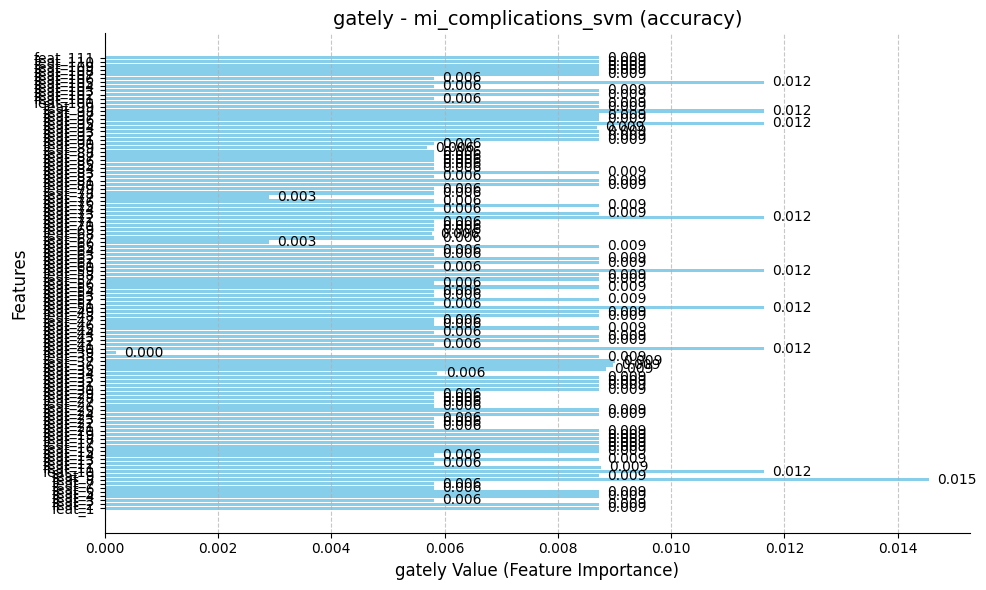

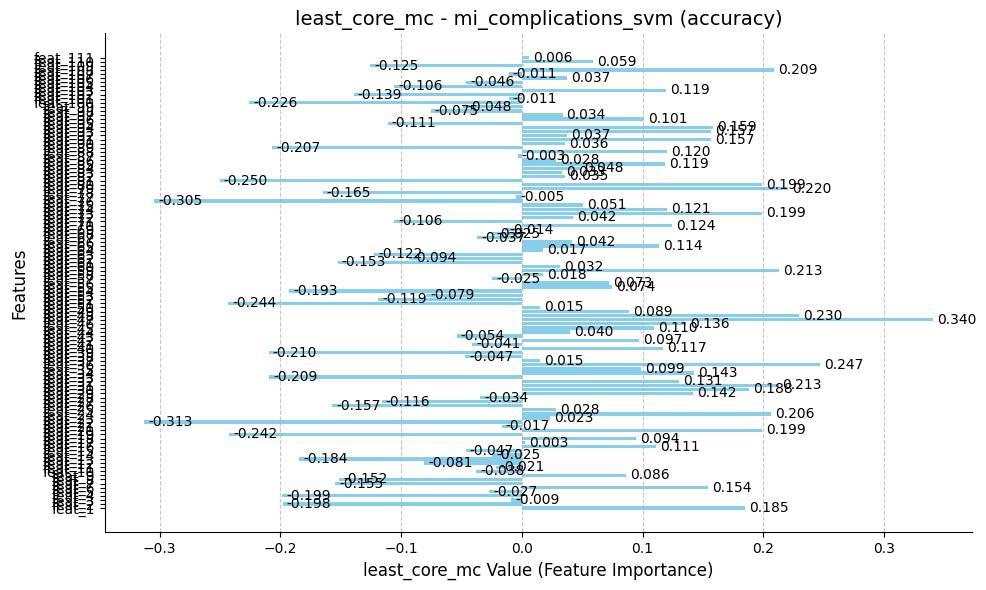

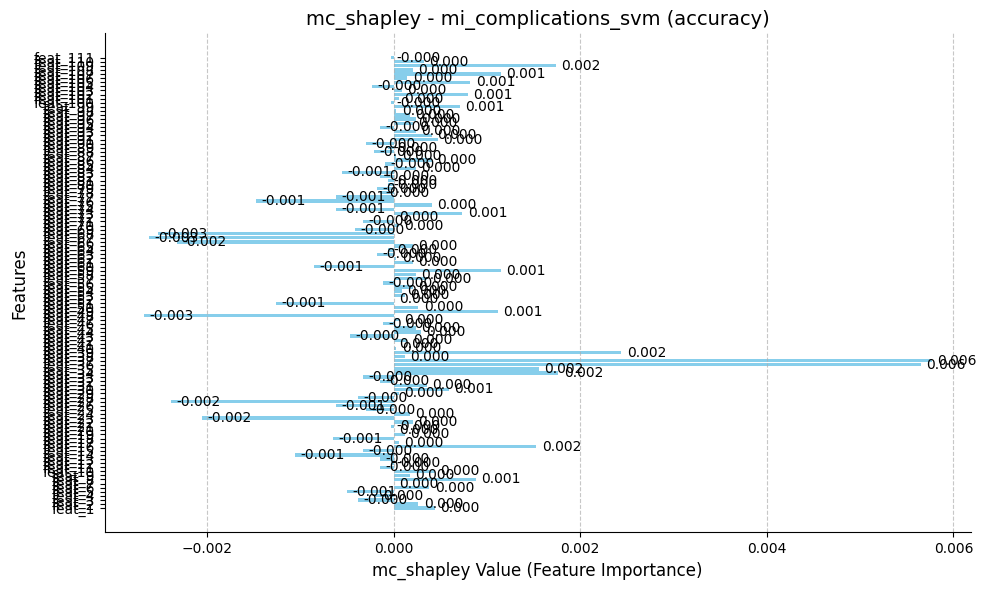

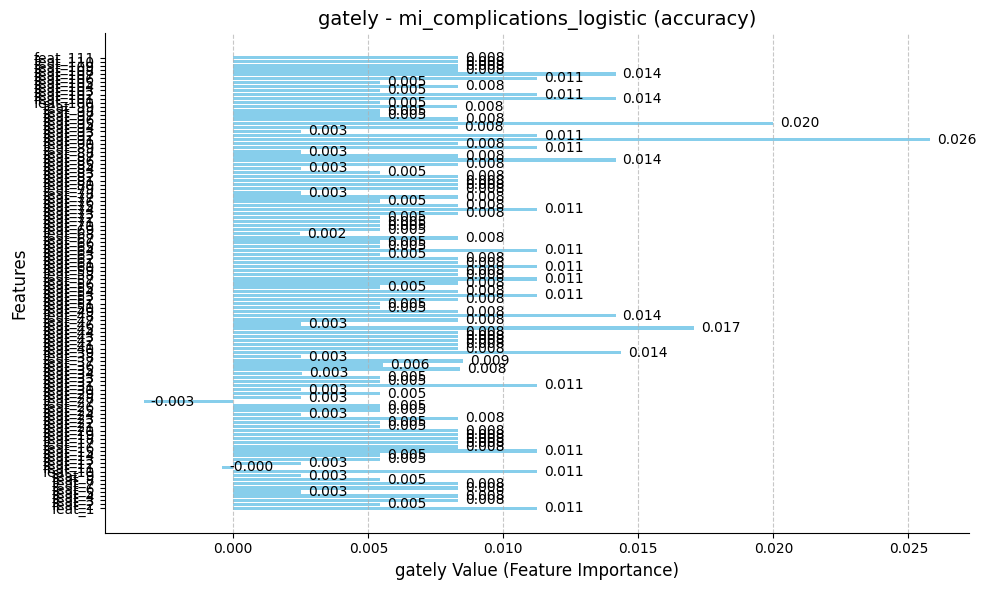

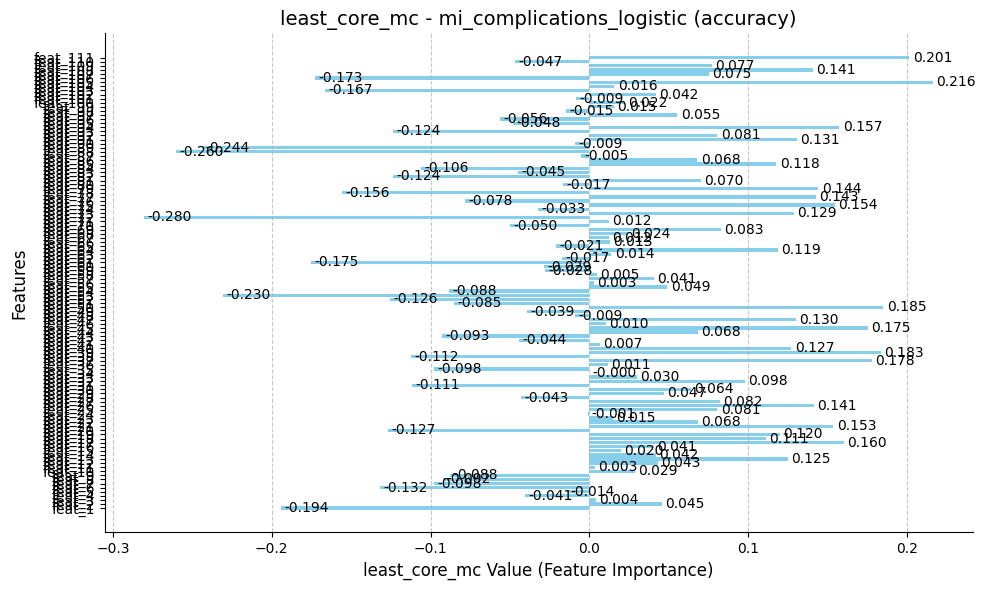

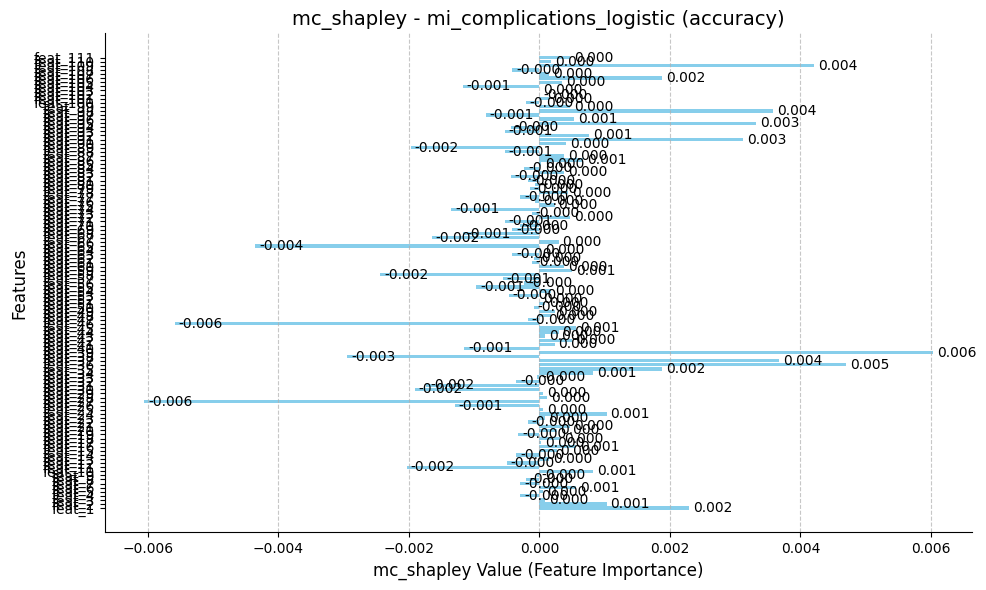

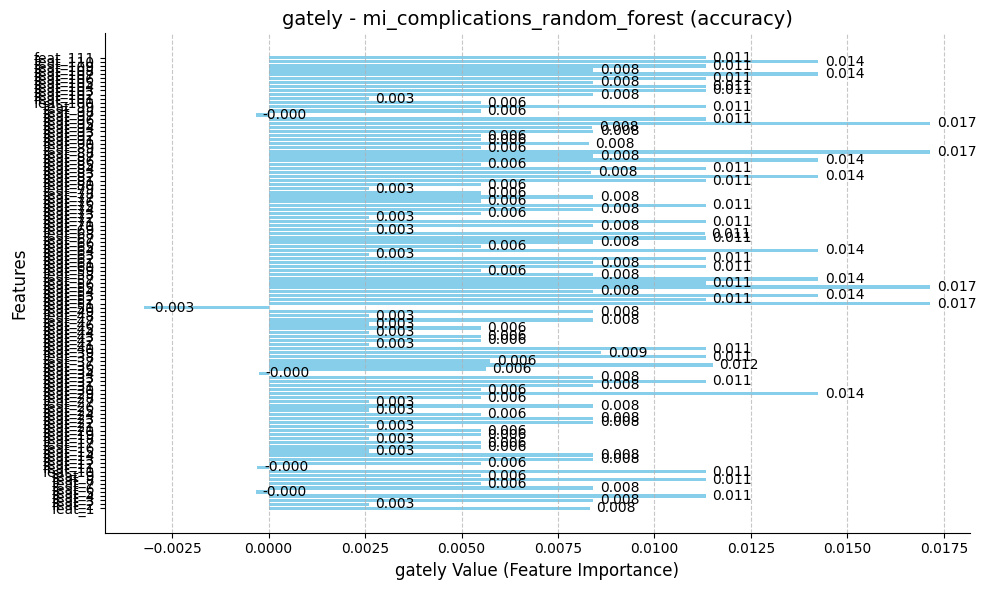

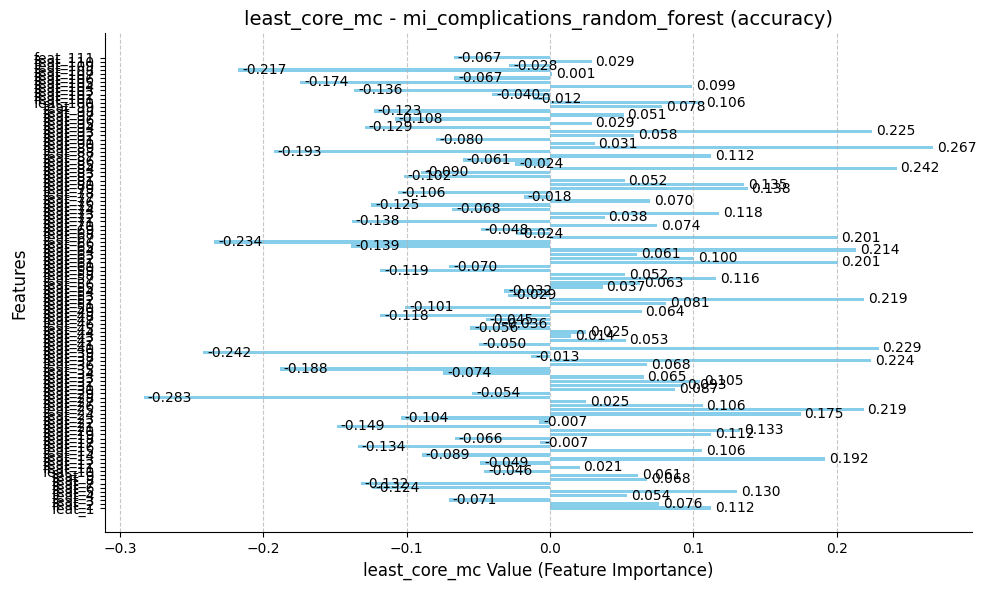

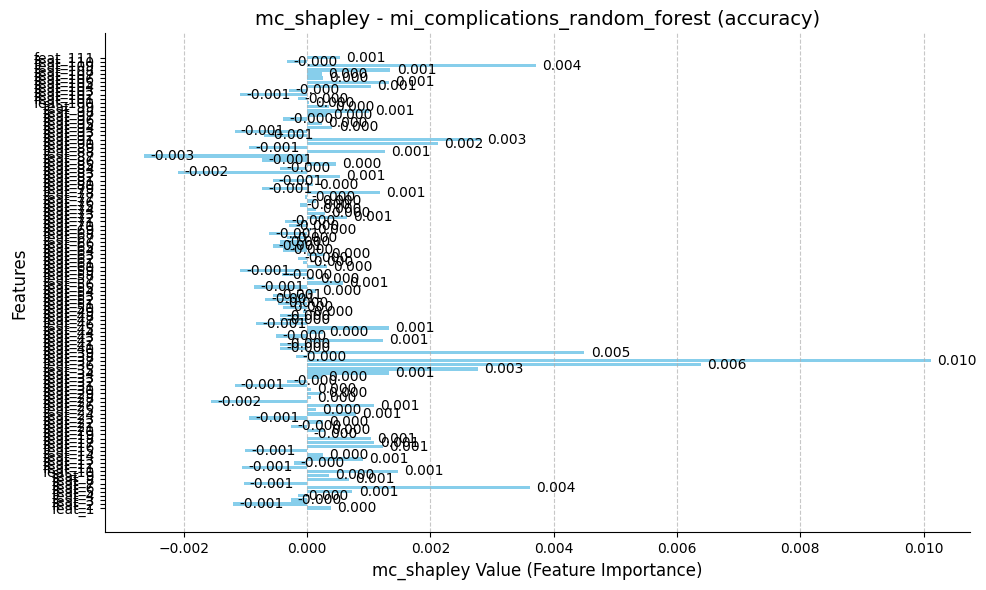

In [3]:
"""
COMPLETE, CORRECT, WORKING SCRIPT (single drop-in file)

This version fixes ALL the issues you hit:
1) No more IndexError / tiling mismatch (works for ANY PERTURB_BATCH, even when not multiple of n_test)
2) Faithfulness-corr uses sum(|phi|) and FC-like signal (logit/logprob/margin) under SAME deletion protocol
3) Sufficiency uses positive curve score (p_ref / margin) so it won't get stuck at 1.0 due to negative logs
4) Masking baselines use TRAIN ROW sampling (more on-manifold than per-column sampling)
5) REF_MODE configurable: "pred" (model faithfulness) or "true" (ground-truth reference)
6) Least-core solver configurable by a single SOLVER_NAME variable (default "SCS")

Everything else is your original pipeline:
- retraining-game Utility v(S)
- LOO impacts
- attribution methods: gately, least_core_mc, mc_shapley
- robustness metrics
- rankings and master CSVs

Just run this file.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
import sys
import warnings
from typing import Dict, Optional, Literal

from scipy.stats import spearmanr, pearsonr
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, mean_squared_error, r2_score, mean_absolute_error
)

# Add project root to sys.path (robust)
from pathlib import Path as _Path

HERE = _Path.cwd().resolve()
root = None
for p in [HERE] + list(HERE.parents):
    if (p / "gt_concepts").is_dir():
        root = p
        break
if root is None:
    raise RuntimeError(f"Could not find project root containing 'gt_concepts' from {HERE}")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
print("Project root added to sys.path:", root)

# Project imports
from models.train_model import get_model
from utils.plotting import plot_single_valuation

from gt_concepts.gately_point import exact_gately_value
from gt_concepts.least_core import montecarlo_least_core
from gt_concepts.shapley import montecarlo_shapley_value

# Logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Config
DATASETS = ["mi_complications"]  # add "lung_cancer" if desired
MODEL_NAMES = ["svm", "logistic", "random_forest"]
SCORING = "accuracy"  # ONLY for retraining-game utility/LOO
RANDOM_STATE = 42

BASE_OUTPUT_DIR = Path("./output/feature_valuation_uci_paper_eval_multi_master_corrected_FINAL")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Masking curve settings
CURVE_STEPS = 10

# Robustness settings
NOISE_LEVEL = 0.05
BOOTSTRAP_ROUNDS = 10

# Shapley MC settings
SHAPLEY_MC_ITERS = 100

# Least-core settings
LEAST_CORE_MC_ITERS = 300
LEAST_CORE_EPSILON = 1e-6

SOLVER_NAME = "SCS"
LEAST_CORE_SOLVER_OPTS = {
    "solver": SOLVER_NAME,
    "max_iters": 25000,
    "eps": 1e-6,
    "verbose": False
}

# Faithfulness-corr settings
FC_N_TESTS = 100
FC_SUBSET_SIZE = 20

# Masking perturbation sampling
PERTURB_N_BASELINES = 8       # MC averaging baselines per step
PERTURB_BATCH = 2048          # can be ANY number now
REF_MODE: Literal["pred", "true"] = "pred"  # "pred" recommended (model-faithfulness); "true" for ground truth ref


# Dataset loaders
def load_lung_cancer():
    path = "../datasets/lung-cancer.data"
    df = pd.read_csv(path, header=None, na_values="?")

    y = df.iloc[:, 0].astype(int).values
    X_df = df.iloc[:, 1:]
    feature_names = [f"attr_{i}" for i in range(1, X_df.shape[1] + 1)]

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_mi_complications(binary_let_is=True):
    path = "../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    let_is = df.iloc[:, 123].astype(int).values
    y = (let_is != 0).astype(int) if binary_let_is else let_is

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_dataset(name: str):
    if name == "lung_cancer":
        return load_lung_cancer()
    if name == "mi_complications":
        return load_mi_complications(binary_let_is=True)
    raise ValueError(f"Unknown dataset name: {name}")


# Utility + scorer (retraining game)
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)


class Utility:
    """
    v(S): train model on features S, evaluate on test.
    Includes caching for speed.
    """
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer,
                 feature_names=None, random_state=42):
        self.X_train = np.asarray(X_train)
        self.y_train = np.asarray(y_train)
        self.X_test = np.asarray(X_test)
        self.y_test = np.asarray(y_test)
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(self.X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]

        if len(key) == 0:
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = float(score)
            return float(score)

        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = float(score)
        return float(score)


def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")


# LOO impacts (retraining paradigm)
def loo_impacts(utility: Utility):
    n = len(utility.data)
    all_set = set(range(n))
    vN = utility(list(all_set))
    impacts = np.zeros(n, dtype=float)
    for i in range(n):
        vN_minus_i = utility(list(all_set - {i}))
        impacts[i] = vN - vN_minus_i
    return float(vN), impacts


# Robustness helpers
def cosine(a, b):
    return float(np.dot(a, b) / ((np.linalg.norm(a) * np.linalg.norm(b)) + 1e-12))


def noise_stability_cosine(base_utility: Utility, method_fn, noise_level: float = 0.05):
    phi0 = method_fn(base_utility)

    X_train = base_utility.X_train
    noise = np.random.normal(0, noise_level * X_train.std(axis=0), X_train.shape)
    X_noisy = X_train + noise

    util_noisy = Utility(
        X_noisy, base_utility.y_train, base_utility.X_test, base_utility.y_test,
        model_name=base_utility.model_name,
        scorer=base_utility.scorer,
        feature_names=base_utility.data.data_names,
        random_state=base_utility.random_state + 11
    )
    phi_noisy = method_fn(util_noisy)
    return cosine(phi0, phi_noisy)


def bootstrap_stability_cosine(base_utility: Utility, method_fn, rounds: int = 10):
    X_train = base_utility.X_train
    y_train = base_utility.y_train
    X_test = base_utility.X_test
    y_test = base_utility.y_test

    phi0 = method_fn(base_utility)

    rng = np.random.default_rng(base_utility.random_state)
    n = X_train.shape[0]
    cos_list = []
    for r in range(rounds):
        idx = rng.integers(0, n, size=n)
        Xb = X_train[idx]
        yb = y_train[idx]

        util_b = Utility(
            Xb, yb, X_test, y_test,
            model_name=base_utility.model_name,
            scorer=base_utility.scorer,
            feature_names=base_utility.data.data_names,
            random_state=base_utility.random_state + 1000 + r
        )
        phi_b = method_fn(util_b)
        cos_list.append(cosine(phi0, phi_b))

    return float(np.mean(cos_list))


# Attribution methods
def gately_method_fn(utility: Utility) -> np.ndarray:
    res = exact_gately_value(utility, options=None, progress=False)
    return np.array(res.values, dtype=float)


def least_core_mc_method_fn(utility: Utility) -> np.ndarray:
    res = montecarlo_least_core(
        utility,
        n_iterations=LEAST_CORE_MC_ITERS,
        epsilon=LEAST_CORE_EPSILON,
        options=LEAST_CORE_SOLVER_OPTS,
        progress=False
    )
    return np.array(res.values, dtype=float)


def shapley_mc_method_fn(utility: Utility) -> np.ndarray:
    res = montecarlo_shapley_value(
        utility,
        n_iterations=SHAPLEY_MC_ITERS,
        options=None,
        progress=False
    )
    return np.array(res.values, dtype=float)


ATTRIBUTION_METHODS = {
    "gately": gately_method_fn,
    "least_core_mc": least_core_mc_method_fn,
    "mc_shapley": shapley_mc_method_fn,
}


class TrainRowMaskingEvaluator:
    """
    Masking metrics with TRAIN-row baselines.

    REF_MODE:
      - "pred": reference is model predicted class on original X_test
      - "true": reference is y_test (ground truth)

    Curve signal (DEL/INS/Suff):
      - proba: p(ref)
      - decision_function: signed margin toward ref
      - fallback: 1s (won't crash; avoid relying on this)
    FC signal:
      - proba: logit(p_ref) for binary, log(p_ref) for multiclass
      - decision_function: signed margin
    """

    def __init__(
        self,
        model,
        X_train: np.ndarray,
        X_test: np.ndarray,
        y_test: np.ndarray,
        ref_mode: Literal["pred", "true"] = "pred",
        rng_seed: int = 42,
    ):
        self.model = model
        self.X_train = np.asarray(X_train)
        self.X_test = np.asarray(X_test)
        self.y_test = np.asarray(y_test)
        self.ref_mode = ref_mode
        self.rng = np.random.default_rng(rng_seed)

        self._has_proba = hasattr(model, "predict_proba") and callable(getattr(model, "predict_proba"))
        self._has_decision = hasattr(model, "decision_function") and callable(getattr(model, "decision_function"))
        self._classes = getattr(model, "classes_", None)

        self._ref_idx = self._compute_ref()  # (n_test,) in index space for proba; labels otherwise

        self._orig_curve_signal = self._curve_signal(self.X_test, ref_idx=self._ref_idx)
        self._orig_fc_signal = self._fc_signal(self.X_test, ref_idx=self._ref_idx)

    def _map_labels_to_class_index(self, y: np.ndarray) -> np.ndarray:
        if self._classes is None:
            return y.astype(int)
        cls_to_i = {c: i for i, c in enumerate(self._classes)}
        return np.array([cls_to_i[yy] for yy in y], dtype=int)

    def _compute_ref(self) -> np.ndarray:
        if self._has_proba:
            if self.ref_mode == "pred":
                y_ref = self.model.predict(self.X_test)
            else:
                y_ref = self.y_test
            return self._map_labels_to_class_index(y_ref)
        else:
            # decision-only: keep labels
            if self.ref_mode == "pred":
                return self.model.predict(self.X_test)
            else:
                return self.y_test

    def _curve_signal(self, X: np.ndarray, ref_idx: np.ndarray) -> np.ndarray:
        n = X.shape[0]
        ref = np.asarray(ref_idx)
        if ref.shape[0] != n:
            raise ValueError(f"curve_signal: ref length {ref.shape[0]} != n {n}")

        if self._has_proba:
            proba = self.model.predict_proba(X)
            ref = ref.astype(int)
            return proba[np.arange(n), ref]

        if self._has_decision:
            dec = self.model.decision_function(X)
            if dec.ndim == 1:
                # binary signed margin toward ref (label-based)
                if self._classes is not None and len(self._classes) == 2:
                    pos_label = self._classes[1]
                    sign = np.where(ref == pos_label, 1.0, -1.0)
                else:
                    sign = np.where(ref == 1, 1.0, -1.0)
                return sign * dec
            else:
                # multiclass: need indices; if we don't have, fallback to max
                try:
                    refi = ref.astype(int)
                    return dec[np.arange(n), refi]
                except Exception:
                    return dec.max(axis=1)

        return np.ones(n, dtype=float)

    def _fc_signal(self, X: np.ndarray, ref_idx: np.ndarray) -> np.ndarray:
        eps = 1e-12
        n = X.shape[0]
        ref = np.asarray(ref_idx)
        if ref.shape[0] != n:
            raise ValueError(f"fc_signal: ref length {ref.shape[0]} != n {n}")

        if self._has_proba:
            proba = self.model.predict_proba(X)
            ref = ref.astype(int)
            p_ref = proba[np.arange(n), ref]
            if proba.shape[1] == 2:
                return np.log(p_ref + eps) - np.log(1.0 - p_ref + eps)
            else:
                return np.log(p_ref + eps)

        # decision / fallback: use curve signal (margin)
        return self._curve_signal(X, ref_idx=ref)

    def _sample_train_rows_matrix(self, n_baselines: int, n_test: int) -> np.ndarray:
        idx = self.rng.integers(0, self.X_train.shape[0], size=(n_baselines, n_test))
        return self.X_train[idx]

    def _make_deletion_batch(self, cols_remove: np.ndarray, n_baselines: int) -> np.ndarray:
        n_test, d = self.X_test.shape
        base = self._sample_train_rows_matrix(n_baselines, n_test)
        X_stack = np.repeat(self.X_test[None, :, :], n_baselines, axis=0)
        X_stack[:, :, cols_remove] = base[:, :, cols_remove]
        return X_stack.reshape(n_baselines * n_test, d)

    def _make_insertion_batch(self, cols_keep: np.ndarray, n_baselines: int) -> np.ndarray:
        n_test, d = self.X_test.shape
        base = self._sample_train_rows_matrix(n_baselines, n_test)
        if cols_keep.size > 0:
            base[:, :, cols_keep] = self.X_test[None, :, cols_keep]
        return base.reshape(n_baselines * n_test, d)

    def _batched_mean(self, X_big: np.ndarray, n_baselines: int, which: str, batch_size: int) -> float:
        """
        No tiling assumptions inside chunks.
        We prebuild ref_big for the full (B*n_test) batch, then slice alongside Xc.
        """
        n_test = self.X_test.shape[0]
        ref_big = np.tile(self._ref_idx, n_baselines)  # length B*n_test

        sig_parts = []
        for start in range(0, X_big.shape[0], batch_size):
            end = min(start + batch_size, X_big.shape[0])
            Xc = X_big[start:end]
            refc = ref_big[start:end]

            if which == "curve":
                sig_parts.append(self._curve_signal(Xc, ref_idx=refc))
            elif which == "fc":
                sig_parts.append(self._fc_signal(Xc, ref_idx=refc))
            else:
                raise ValueError("which must be 'curve' or 'fc'")

        sig = np.concatenate(sig_parts, axis=0)
        return float(sig.mean())

    def masking_curve_auc(self, order: np.ndarray, steps: int, mode: str, n_baselines: int, batch_size: int) -> float:
        fracs = np.linspace(0.0, 1.0, steps)
        scores = []
        d = len(order)

        base_curve_score = float(self._orig_curve_signal.mean())

        for f in fracs:
            k = int(round(f * d))
            cols = order[:k] if k > 0 else np.array([], dtype=int)

            if mode == "deletion":
                if cols.size == 0:
                    score = base_curve_score
                else:
                    X_big = self._make_deletion_batch(cols, n_baselines)
                    score = self._batched_mean(X_big, n_baselines=n_baselines, which="curve", batch_size=batch_size)
            elif mode == "insertion":
                X_big = self._make_insertion_batch(cols, n_baselines)
                score = self._batched_mean(X_big, n_baselines=n_baselines, which="curve", batch_size=batch_size)
            else:
                raise ValueError("mode must be 'deletion' or 'insertion'")

            scores.append(score)

        return float(np.trapezoid(np.array(scores), fracs))

    def deletion_auc_drop(self, attribution: np.ndarray, steps: int, n_baselines: int, batch_size: int, rng_seed: int = 42) -> float:
        order_attr = np.argsort(-np.abs(attribution))
        order_rand = np.random.default_rng(rng_seed).permutation(len(attribution))
        auc_attr = self.masking_curve_auc(order_attr, steps, "deletion", n_baselines=n_baselines, batch_size=batch_size)
        auc_rand = self.masking_curve_auc(order_rand, steps, "deletion", n_baselines=n_baselines, batch_size=batch_size)
        return float(auc_rand - auc_attr)

    def insertion_auc_gain(self, attribution: np.ndarray, steps: int, n_baselines: int, batch_size: int, rng_seed: int = 42) -> float:
        order_attr = np.argsort(-np.abs(attribution))
        order_rand = np.random.default_rng(rng_seed).permutation(len(attribution))
        auc_attr = self.masking_curve_auc(order_attr, steps, "insertion", n_baselines=n_baselines, batch_size=batch_size)
        auc_rand = self.masking_curve_auc(order_rand, steps, "insertion", n_baselines=n_baselines, batch_size=batch_size)
        return float(auc_attr - auc_rand)

    def faithfulness_corr(self, attribution: np.ndarray, n_tests: int, subset_size: int, n_baselines: int, batch_size: int) -> float:
        abs_attr = np.abs(attribution)
        d = len(attribution)
        k = min(int(subset_size), max(1, d // 2))
        rng = np.random.default_rng(42)

        base_fc_score = float(self._orig_fc_signal.mean())

        x = np.empty(n_tests, dtype=float)
        y = np.empty(n_tests, dtype=float)

        for t in range(n_tests):
            subset = rng.choice(d, size=k, replace=False)
            x[t] = float(abs_attr[subset].sum())
            X_big = self._make_deletion_batch(subset, n_baselines)
            score_mask = self._batched_mean(X_big, n_baselines=n_baselines, which="fc", batch_size=batch_size)
            y[t] = float(base_fc_score - score_mask)

        corr, _ = pearsonr(x, y)
        return float(corr)

    def sufficiency_multi(self, attribution: np.ndarray, thresholds=(0.8, 0.9, 0.95), n_baselines: int = 8, batch_size: int = 2048) -> Dict[str, float]:
        abs_attr = np.abs(attribution)
        order = np.argsort(-abs_attr)
        d = len(order)

        full_score = float(self._orig_curve_signal.mean())  # positive p_ref (or margin)
        out: Dict[str, float] = {}

        for thr in thresholds:
            target = thr * full_score
            found = False
            for kk in range(1, d + 1):
                cols = order[:kk]
                X_big = self._make_insertion_batch(cols, n_baselines)
                score_k = self._batched_mean(X_big, n_baselines=n_baselines, which="curve", batch_size=batch_size)
                if score_k >= target:
                    out[f"sufficiency_{int(thr*100)}"] = float(kk / d)
                    found = True
                    break
            if not found:
                out[f"sufficiency_{int(thr*100)}"] = 1.0

        return out

    def evaluate_masking_metrics(self, attribution: np.ndarray, steps: int, n_baselines: int, batch_size: int) -> Dict[str, float]:
        return {
            "deletion_auc_drop": self.deletion_auc_drop(attribution, steps, n_baselines=n_baselines, batch_size=batch_size, rng_seed=42),
            "insertion_auc_gain": self.insertion_auc_gain(attribution, steps, n_baselines=n_baselines, batch_size=batch_size, rng_seed=42),
            "faithfulness_corr": self.faithfulness_corr(attribution, n_tests=FC_N_TESTS, subset_size=FC_SUBSET_SIZE, n_baselines=n_baselines, batch_size=batch_size),
            **self.sufficiency_multi(attribution, thresholds=(0.8, 0.9, 0.95), n_baselines=n_baselines, batch_size=batch_size),
        }


# Ranking helpers
def rank_methods(metric_df: pd.DataFrame, higher_is_better_cols):
    rank_df = pd.DataFrame(index=metric_df.index)
    for col in metric_df.columns:
        higher = col in higher_is_better_cols
        rank_df[col] = metric_df[col].rank(ascending=not higher, method="average")
    return rank_df


def rank_summary(rank_df: pd.DataFrame):
    return pd.DataFrame({
        "mean_rank_mu_hat": rank_df.mean(axis=1),
        "std_rank_sigma_hat": rank_df.std(axis=1, ddof=0)
    }).sort_values("mean_rank_mu_hat")


# Main
def main():
    scorer = get_scorer(SCORING)

    master_rows_faith = []
    master_rows_rob = []
    master_rows_faith_rank = []
    master_rows_rob_rank = []
    master_rows_faith_summary = []
    master_rows_rob_summary = []

    for dataset_name in DATASETS:
        X_train, X_test, y_train, y_test, feature_names = load_dataset(dataset_name)

        for model_name in MODEL_NAMES:
            logger.info("\n" + "=" * 70)
            logger.info(f"DATASET: {dataset_name} | MODEL: {model_name}")
            logger.info("=" * 70)

            OUTPUT_DIR = BASE_OUTPUT_DIR / f"{dataset_name}_{model_name}_results"
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

            # retraining-game utility
            utility = Utility(
                X_train, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            # Train full model ONCE for masking metrics
            full_model = get_model(model_name, RANDOM_STATE)
            full_model.fit(X_train, y_train)

            evaluator = TrainRowMaskingEvaluator(
                full_model, X_train, X_test, y_test,
                ref_mode=REF_MODE,
                rng_seed=RANDOM_STATE
            )

            vN, impacts = loo_impacts(utility)
            logger.info(f"  v(N) with all features ({SCORING}) = {vN:.4f}")
            logger.info(f"  Masking REF_MODE={REF_MODE} | baselines={PERTURB_N_BASELINES} | batch={PERTURB_BATCH} | FC tests={FC_N_TESTS}")

            # Compute attributions (retraining game)
            attributions = {}
            for mname, mfn in ATTRIBUTION_METHODS.items():
                logger.info(f"Computing attributions: {mname}")
                phi = mfn(utility)
                attributions[mname] = phi

                df_vals = pd.DataFrame({"method": mname, "feature": feature_names, "value": phi})
                df_vals.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_feature_valuations_{mname}.csv", index=False)

                try:
                    plot_single_valuation(
                        phi, feature_names,
                        method_name=mname,
                        title=f"{mname} - {dataset_name}_{model_name} ({SCORING})",
                        output_path=OUTPUT_DIR / f"{dataset_name}_{model_name}_{mname}.png"
                    )
                except Exception as e:
                    logger.warning(f"Plot failed for {mname}: {e}")

            # Faithfulness metrics
            faith_rows = []
            for mname, phi in attributions.items():
                sp, p_sp = spearmanr(phi, impacts)
                pe, p_pe = pearsonr(phi, impacts)

                mask_metrics = evaluator.evaluate_masking_metrics(
                    phi, steps=CURVE_STEPS, n_baselines=PERTURB_N_BASELINES, batch_size=PERTURB_BATCH
                )

                row = {
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": mname,
                    "loo_spearman": float(sp),
                    "loo_pearson": float(pe),
                    "_p_spearman": float(p_sp),
                    "_p_pearson": float(p_pe),
                    "vN": float(vN),
                    **mask_metrics,
                }
                faith_rows.append(row)
                master_rows_faith.append(row)

            faith_df = pd.DataFrame(faith_rows).set_index("method")
            faith_df.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_faithfulness_metrics_raw.csv")
            logger.info("\nFaithfulness metrics (raw):\n" + faith_df.to_string())

            # Robustness metrics
            rob_rows = []
            for mname, mfn in ATTRIBUTION_METHODS.items():
                noise_cos = noise_stability_cosine(utility, mfn, noise_level=NOISE_LEVEL)
                boot_cos = bootstrap_stability_cosine(utility, mfn, rounds=BOOTSTRAP_ROUNDS)
                rob_rows.append({
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": mname,
                    "noise_cosine": float(noise_cos),
                    "bootstrap_cosine": float(boot_cos),
                })
                master_rows_rob.append(rob_rows[-1])

            rob_df = pd.DataFrame(rob_rows).set_index("method")
            rob_df.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_robustness_metrics_raw.csv")
            logger.info("\nRobustness metrics (raw):\n" + rob_df.to_string())

            # Ranking
            faith_metric_cols = [
                c for c in faith_df.columns
                if (not c.startswith("_")) and (c not in ["dataset", "model", "vN"])
            ]
            rob_metric_cols = ["noise_cosine", "bootstrap_cosine"]

            faith_rank = pd.DataFrame(index=faith_df.index)
            for col in faith_metric_cols:
                higher = not col.startswith("sufficiency_")  # sufficiency lower is better
                faith_rank[col] = faith_df[col].rank(ascending=not higher, method="average")

            rob_rank = rank_methods(rob_df[rob_metric_cols], higher_is_better_cols=set(rob_metric_cols))

            faith_rank.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_faithfulness_ranks.csv")
            rob_rank.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_robustness_ranks.csv")

            for method in faith_rank.index:
                r = {"dataset": dataset_name, "model": model_name, "method": method}
                r.update({f"rank_{c}": float(faith_rank.loc[method, c]) for c in faith_metric_cols})
                master_rows_faith_rank.append(r)

            for method in rob_rank.index:
                r = {"dataset": dataset_name, "model": model_name, "method": method}
                r.update({f"rank_{c}": float(rob_rank.loc[method, c]) for c in rob_metric_cols})
                master_rows_rob_rank.append(r)

            # Mean rank summary
            faith_summary = rank_summary(faith_rank)
            rob_summary = rank_summary(rob_rank)

            faith_summary.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_faithfulness_rank_summary.csv")
            rob_summary.to_csv(OUTPUT_DIR / f"{dataset_name}_{model_name}_robustness_rank_summary.csv")

            logger.info("\nFaithfulness rank summary (μ̂, σ̂):\n" + faith_summary.to_string())
            logger.info("\nRobustness rank summary (μ̂, σ̂):\n" + rob_summary.to_string())

            for method in faith_summary.index:
                master_rows_faith_summary.append({
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": method,
                    "faith_mean_rank_mu_hat": float(faith_summary.loc[method, "mean_rank_mu_hat"]),
                    "faith_std_rank_sigma_hat": float(faith_summary.loc[method, "std_rank_sigma_hat"]),
                })
            for method in rob_summary.index:
                master_rows_rob_summary.append({
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": method,
                    "rob_mean_rank_mu_hat": float(rob_summary.loc[method, "mean_rank_mu_hat"]),
                    "rob_std_rank_sigma_hat": float(rob_summary.loc[method, "std_rank_sigma_hat"]),
                })

            logger.info(f"\nSaved per-run outputs to: {OUTPUT_DIR}")
            logger.info("=" * 70)

    # MASTER CSVs
    master_faith = pd.DataFrame(master_rows_faith)
    master_rob = pd.DataFrame(master_rows_rob)
    master_faith_rank = pd.DataFrame(master_rows_faith_rank)
    master_rob_rank = pd.DataFrame(master_rows_rob_rank)
    master_faith_summary = pd.DataFrame(master_rows_faith_summary)
    master_rob_summary = pd.DataFrame(master_rows_rob_summary)

    paper_master = master_faith.merge(master_rob, on=["dataset", "model", "method"], how="outer")
    paper_master = paper_master.merge(master_faith_summary, on=["dataset", "model", "method"], how="outer")
    paper_master = paper_master.merge(master_rob_summary, on=["dataset", "model", "method"], how="outer")

    master_faith_path = BASE_OUTPUT_DIR / "MASTER_faithfulness_raw.csv"
    master_rob_path = BASE_OUTPUT_DIR / "MASTER_robustness_raw.csv"
    master_faith_rank_path = BASE_OUTPUT_DIR / "MASTER_faithfulness_ranks.csv"
    master_rob_rank_path = BASE_OUTPUT_DIR / "MASTER_robustness_ranks.csv"
    paper_master_path = BASE_OUTPUT_DIR / "MASTER_paper_table.csv"

    master_faith.to_csv(master_faith_path, index=False)
    master_rob.to_csv(master_rob_path, index=False)
    master_faith_rank.to_csv(master_faith_rank_path, index=False)
    master_rob_rank.to_csv(master_rob_rank_path, index=False)
    paper_master.to_csv(paper_master_path, index=False)

    logger.info("\nMASTER CSVs saved:")
    logger.info(f"  {master_faith_path}")
    logger.info(f"  {master_rob_path}")
    logger.info(f"  {master_faith_rank_path}")
    logger.info(f"  {master_rob_rank_path}")
    logger.info(f"  {paper_master_path}")


if __name__ == "__main__":
    main()

In [ ]:
"""
PUBLICATION-READY PRIME Implementation (FINAL PATCHED VERSION)
All fixes applied:
1. Precomputed signatures (no repeated inspect overhead) 
2. Fixed verify_determinism with robust .get() 
3. Adjusted wording: "best-effort determinism" 
"""

import numpy as np
import pandas as pd
from dataclasses import dataclass
from typing import Callable, Dict, List, Optional
from pathlib import Path
import inspect

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score

# Import project modules at top
import sys
sys.path.insert(0, str(Path.cwd()))

from models.train_model import get_model

# Import attribution functions ONCE at module level
from gt_concepts.gately_point import exact_gately_value
from gt_concepts.shapley import montecarlo_shapley_value
from gt_concepts.least_core import montecarlo_least_core

_SHAPLEY_SIG = inspect.signature(montecarlo_shapley_value)
_LEASTCORE_SIG = inspect.signature(montecarlo_least_core)

# Utility class (unchanged)
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)


class Utility:
    """v(S): train model on features S, evaluate on test."""
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer,
                 feature_names=None, random_state=42):
        self.X_train = np.asarray(X_train)
        self.y_train = np.asarray(y_train)
        self.X_test = np.asarray(X_test)
        self.y_test = np.asarray(y_test)
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(self.X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]

        if len(key) == 0:
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = float(score)
            return float(score)

        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = float(score)
        return float(score)


# Attribution methods with best-effort determinism
def gately_attribution(utility: Utility) -> Dict[str, float]:
    """Gately (exact, deterministic by design)."""
    res = exact_gately_value(utility, options=None, progress=False)
    return {utility.data.data_names[i]: float(res.values[i]) for i in range(len(res.values))}


def mc_shapley_attribution(utility: Utility, n_iterations: int = 500) -> Dict[str, float]:
    """
    MC Shapley with best-effort determinism (verified via verify_determinism).

    Uses multiple approaches to control randomness:
    - Direct random_state parameter (if supported)
    - random_state in options dict
    - Legacy np.random.seed() fallback
    """
    np.random.seed(utility.random_state)

    sig = _SHAPLEY_SIG

    try:
        if 'random_state' in sig.parameters:
            res = montecarlo_shapley_value(
                utility,
                n_iterations=n_iterations,
                random_state=utility.random_state,
                progress=False
            )
        else:
            res = montecarlo_shapley_value(
                utility,
                n_iterations=n_iterations,
                options={"random_state": utility.random_state},
                progress=False
            )
    except (TypeError, KeyError):
        res = montecarlo_shapley_value(
            utility,
            n_iterations=n_iterations,
            options=None,
            progress=False
        )

    return {utility.data.data_names[i]: float(res.values[i]) for i in range(len(res.values))}


def least_core_attribution(utility: Utility, n_iterations: int = 500) -> Dict[str, float]:
    """
    Least Core with best-effort determinism (verified via verify_determinism).

    Uses multiple approaches to control randomness:
    - Direct random_state parameter (if supported)
    - random_state in options dict
    - Legacy np.random.seed() fallback
    """
    np.random.seed(utility.random_state)

    sig = _LEASTCORE_SIG

    try:
        if 'random_state' in sig.parameters:
            res = montecarlo_least_core(
                utility,
                n_iterations=n_iterations,
                epsilon=1e-6,
                random_state=utility.random_state,
                options={
                    "solver": "SCS",
                    "max_iters": 25000,
                    "eps": 1e-6,
                    "verbose": False,
                },
                progress=False
            )
        else:
            res = montecarlo_least_core(
                utility,
                n_iterations=n_iterations,
                epsilon=1e-6,
                options={
                    "solver": "SCS",
                    "max_iters": 25000,
                    "eps": 1e-6,
                    "verbose": False,
                    "random_state": utility.random_state,
                },
                progress=False
            )
    except (TypeError, KeyError):
        res = montecarlo_least_core(
            utility,
            n_iterations=n_iterations,
            epsilon=1e-6,
            options={
                "solver": "SCS",
                "max_iters": 25000,
                "eps": 1e-6,
                "verbose": False,
            },
            progress=False
        )

    return {utility.data.data_names[i]: float(res.values[i]) for i in range(len(res.values))}


# Data loading (unchanged)
def load_mi_complications(binary_let_is=True, random_state=42):
    """Load MI complications dataset."""
    path = "../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    let_is = df.iloc[:, 123].astype(int).values
    y = (let_is != 0).astype(int) if binary_let_is else let_is

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=random_state
    )
    return X_train, X_test, y_train, y_test, feature_names


# Permutation importance weights
def compute_permutation_weights(
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_test: np.ndarray,
    y_test: np.ndarray,
    feature_names: List[str],
    model_name: str = "svm",
    scorer=accuracy_score,
    n_repeats: int = 50,
    seed: int = 42,
    verbose: bool = False,
) -> Dict[str, float]:
    """
    Compute permutation importance weights w_i (standard definition).

    Note: Test-set permutation weights for predictive relevance,
    while PRIME measures training-perturbation stability.
    """
    rng = np.random.default_rng(seed)

    model = get_model(model_name, seed)
    model.fit(X_train, y_train)

    y_pred_base = model.predict(X_test)
    baseline_score = scorer(y_test, y_pred_base)

    n_features = len(feature_names)
    drops = np.zeros(n_features, dtype=float)

    for feat_idx in range(n_features):
        drop_list = []
        for _ in range(n_repeats):
            X_test_perm = X_test.copy()
            X_test_perm[:, feat_idx] = rng.permutation(X_test_perm[:, feat_idx])

            y_pred_perm = model.predict(X_test_perm)
            perm_score = scorer(y_test, y_pred_perm)

            drop_list.append(baseline_score - perm_score)

        drops[feat_idx] = max(0.0, float(np.mean(drop_list)))

    zero_frac = float((drops <= 1e-12).sum() / n_features)
    if verbose:
        print(f"[permutation weights] {zero_frac:.1%} of features have zero weight")
        print(f"[permutation weights] baseline {scorer.__name__} = {baseline_score:.4f}")

    if drops.sum() <= 1e-12:
        if verbose:
            print("[permutation weights] WARNING: all drops zero, using uniform")
        return {feature_names[i]: 1.0 / n_features for i in range(n_features)}

    w = drops / drops.sum()
    return {feature_names[i]: float(w[i]) for i in range(n_features)}


# Weighted Shannon entropy
def weighted_rank_entropy(
    rank_counts: np.ndarray,
    rank_position_weights: np.ndarray,
    eps: float = 1e-12,
) -> float:
    """Compute weighted Shannon entropy over rank distribution."""
    total = rank_counts.sum()
    if total <= 0:
        return 0.0

    p = rank_counts / total
    w_pos = rank_position_weights / (rank_position_weights.sum() + eps)
    H = -float(np.sum(w_pos * p * np.log2(p + eps)))
    return H


@dataclass
class PrimeResult:
    prime_total: float
    prime_normalized: float
    per_feature_entropy: Dict[str, float]
    per_feature_entropy_normalized: Dict[str, float]
    perm_importance_weights: Dict[str, float]
    rank_position_weights: np.ndarray
    n_rankings: int
    zero_weight_fraction: float


# PRIME: Main computation
def compute_prime(
    attribution_fn: Callable[[Utility], Dict[str, float]],
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_test: np.ndarray,
    y_test: np.ndarray,
    feature_names: List[str],
    model_name: str = "svm",
    scorer=accuracy_score,
    num_permutations: int = 20,
    mc_iterations: int = 500,
    seed: int = 42,
    rank_weight_scheme: str = "harmonic",
    verbose: bool = False,
) -> PrimeResult:
    """
    PRIME: Permutation Relative Importance and uncertainty Measurement Evaluation.

    Methodology:
    - Feature weights w_i: test-set permutation importance (predictive relevance)
    - Stability measure: ranking entropy under training-data perturbations
    - Aggregate: PRIME = Σ_i w_i * H_i, normalized by log2(p)

    Lower PRIME = more consistent rankings under training noise.
    """
    rng = np.random.default_rng(seed)
    p = len(feature_names)

    # Rank position weights
    if rank_weight_scheme == "harmonic":
        w_pos = 1.0 / (np.arange(p, dtype=float) + 1.0)
    elif rank_weight_scheme == "uniform":
        w_pos = np.ones(p, dtype=float)
    elif rank_weight_scheme == "exponential":
        w_pos = np.exp(-0.25 * np.arange(p, dtype=float))
    else:
        raise ValueError("rank_weight_scheme must be 'harmonic', 'uniform', or 'exponential'")

    # Compute test-set permutation importance weights
    if verbose:
        print("Computing test-set permutation importance weights w_i...")

    w_feat = compute_permutation_weights(
        X_train, y_train, X_test, y_test,
        feature_names=feature_names,
        model_name=model_name,
        scorer=scorer,
        n_repeats=50,
        seed=seed + 1000,
        verbose=verbose,
    )

    zero_weight_frac = float(sum(1 for w in w_feat.values() if w <= 1e-12) / p)

    if verbose:
        top5 = sorted(w_feat.items(), key=lambda x: x[1], reverse=True)[:5]
        print(f"Top-5 features by w_i: {[(f, f'{w:.4f}') for f, w in top5]}")

    # Check if attribution function accepts n_iterations
    sig = inspect.signature(attribution_fn)
    supports_n_iter = 'n_iterations' in sig.parameters

    # Training-perturbation stability measurement
    rank_counts = {f: np.zeros(p, dtype=float) for f in feature_names}
    n_rankings = 0

    if verbose:
        print(f"\nMeasuring ranking stability under training perturbations...")
        print(f"  {num_permutations} perms × {p} features = {num_permutations * p} rankings")

    for t in range(num_permutations):
        for feat_idx, permuted_feature in enumerate(feature_names):
            # Permute TRAINING data
            X_train_pert = X_train.copy()
            X_train_pert[:, feat_idx] = rng.permutation(X_train_pert[:, feat_idx])

            # Create Utility with perturbed training data
            utility_pert = Utility(
                X_train_pert, y_train,
                X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=seed + t * p + feat_idx
            )

            # Compute attributions
            if supports_n_iter:
                vals = attribution_fn(utility_pert, n_iterations=mc_iterations)
            else:
                vals = attribution_fn(utility_pert)

            # Rank by absolute value
            ranking = sorted(feature_names, key=lambda f: abs(vals.get(f, 0.0)), reverse=True)

            # Update counts
            for pos, feat in enumerate(ranking):
                rank_counts[feat][pos] += 1.0

            n_rankings += 1

            if verbose and t == 0 and feat_idx < 2:
                print(f"  [sample] permuted={permuted_feature}, top5={ranking[:5]}")

    # Compute entropy per feature
    H = {}
    H_norm = {}
    for feat in feature_names:
        H_feat = weighted_rank_entropy(rank_counts[feat], w_pos)
        H[feat] = H_feat
        H_norm[feat] = H_feat / (np.log2(p) + 1e-12)

    if verbose:
        print(f"\nMost unstable features (highest entropy):")
        for f in sorted(feature_names, key=lambda x: H[x], reverse=True)[:5]:
            print(f"  {f}: H={H[f]:.4f}, H_norm={H_norm[f]:.4f}")

    # Aggregate PRIME
    prime_total = float(sum(w_feat[f] * H[f] for f in feature_names))
    prime_normalized = prime_total / (np.log2(p) + 1e-12)

    if verbose:
        print(f"\nPRIME Results:")
        print(f"  PRIME_total = {prime_total:.4f}")
        print(f"  PRIME_normalized = {prime_normalized:.4f} (lower = more consistent)")
        print(f"  Zero-weight features: {zero_weight_frac:.1%}")
        print(f"  Total rankings collected: {n_rankings}")

    return PrimeResult(
        prime_total=prime_total,
        prime_normalized=prime_normalized,
        per_feature_entropy=H,
        per_feature_entropy_normalized=H_norm,
        perm_importance_weights=w_feat,
        rank_position_weights=w_pos / (w_pos.sum() + 1e-12),
        n_rankings=n_rankings,
        zero_weight_fraction=zero_weight_frac,
    )


# Determinism verification helper
def verify_determinism(
    attribution_fn: Callable,
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_test: np.ndarray,
    y_test: np.ndarray,
    feature_names: List[str],
    model_name: str = "svm",
    seed: int = 42,
    det_mc_iterations: int = 25,
    n_trials: int = 3,
) -> bool:
    """
    Verify that attribution function produces identical results with same seed.
    Returns True if all trials match exactly, False otherwise.
    """
    print(f"Verifying determinism for {attribution_fn.__name__}...")

    results = []
    sig = inspect.signature(attribution_fn)
    supports_n_iter = 'n_iterations' in sig.parameters

    for _ in range(n_trials):
        utility = Utility(
            X_train, y_train, X_test, y_test,
            model_name=model_name,
            scorer=accuracy_score,
            feature_names=feature_names,
            random_state=seed
        )

        if supports_n_iter:
            vals = attribution_fn(utility, n_iterations=det_mc_iterations)
        else:
            vals = attribution_fn(utility)

        results.append(vals)

    first = results[0]
    all_match = True
    for r in results[1:]:
        for f in feature_names:
            if abs(r.get(f, 0.0) - first.get(f, 0.0)) >= 1e-10:
                all_match = False
                break
        if not all_match:
            break

    if all_match:
        print(f"  Deterministic: {n_trials} trials produced identical results")
    else:
        print(f"  Error: NON-deterministic: results differ across trials")
        max_diff = 0.0
        for r in results[1:]:
            max_diff = max(
                max_diff,
                max(abs(r.get(f, 0.0) - first.get(f, 0.0)) for f in feature_names)
            )
        print(f"     Max difference (worst over trials): {max_diff:.6e}")

    return all_match


# Run PRIME for all methods
def run_prime_mi_complications(
    model_name: str = "svm",
    num_permutations: int = 20,
    mc_iterations: int = 500,
    seed: int = 42,
    verify_determinism_first: bool = True,
    verbose: bool = True,
):
    """Run PRIME evaluation on MI complications dataset."""
    print("="*70)
    print("PRIME Evaluation: mi_complications")
    print("="*70)
    print(f"Model: {model_name}")
    print(f"MC iterations: {mc_iterations}")
    print(f"Training perturbations: {num_permutations}")
    print(f"Weight computation: test-set permutation importance (accuracy)")
    print(f"Stability measure: ranking entropy under training noise")
    print("="*70)

    # Load data
    X_train, X_test, y_train, y_test, feature_names = load_mi_complications(
        binary_let_is=True,
        random_state=seed
    )

    print(f"\nDataset: n_train={X_train.shape[0]}, n_test={X_test.shape[0]}, n_features={len(feature_names)}")

    # Attribution methods
    attribution_methods = {
        "gately": gately_attribution,
        "mc_shapley": mc_shapley_attribution,
        "least_core_mc": least_core_attribution,
    }

    # Verify determinism before running full PRIME
    if verify_determinism_first:
        print(f"\n{'='*70}")
        print("Determinism Verification")
        print("="*70)
        for method_name, attrib_fn in attribution_methods.items():
            verify_determinism(
                attrib_fn, X_train, y_train, X_test, y_test,
                feature_names, model_name,seed, det_mc_iterations=25, n_trials=3
            )
        print()

    # Run PRIME
    results = []
    for method_name, attrib_fn in attribution_methods.items():
        print(f"\n{'='*70}")
        print(f"Method: {method_name}")
        print(f"{'='*70}")

        prime_res = compute_prime(
            attribution_fn=attrib_fn,
            X_train=X_train,
            y_train=y_train,
            X_test=X_test,
            y_test=y_test,
            feature_names=feature_names,
            model_name=model_name,
            scorer=accuracy_score,
            num_permutations=num_permutations,
            mc_iterations=mc_iterations,
            seed=seed,
            rank_weight_scheme="harmonic",
            verbose=verbose,
        )

        results.append({
            "dataset": "mi_complications",
            "model": model_name,
            "method": method_name,
            "PRIME_total": prime_res.prime_total,
            "PRIME_normalized": prime_res.prime_normalized,
            "zero_weight_pct": prime_res.zero_weight_fraction * 100,
            "n_rankings": prime_res.n_rankings,
            "mc_iterations": mc_iterations,
        })

    # Summary
    df_results = pd.DataFrame(results).sort_values("PRIME_normalized")

    print(f"\n{'='*70}")
    print("PRIME Results Summary")
    print("="*70)
    print("Lower PRIME = more consistent rankings under training perturbations")
    print("="*70)
    print(df_results.to_string(index=False))

    return df_results


# Main
if __name__ == "__main__":
    df_prime = run_prime_mi_complications(
        model_name="svm",
        num_permutations=5,
        mc_iterations=100,
        seed=42,
        verify_determinism_first=False,
        verbose=True,
    )

    # Save
    output_path = Path("./output/PRIME_results_mi_complications_final.csv")
    output_path.parent.mkdir(parents=True, exist_ok=True)
    df_prime.to_csv(output_path, index=False)
    print(f"\nResults saved to: {output_path}")

PRIME Evaluation: mi_complications
Model: svm
MC iterations: 100
Training perturbations: 5
Weight computation: test-set permutation importance (accuracy)
Stability measure: ranking entropy under training noise

Dataset: n_train=1360, n_test=340, n_features=111

Method: gately
Computing test-set permutation importance weights w_i...
[permutation weights] 67.6% of features have zero weight
[permutation weights] baseline accuracy_score = 0.8500
Top-5 features by w_i: [('feat_92', '0.0988'), ('feat_98', '0.0975'), ('feat_99', '0.0711'), ('feat_39', '0.0698'), ('feat_40', '0.0646')]

Measuring ranking stability under training perturbations...
  5 perms × 111 features = 555 rankings
  [sample] permuted=feat_1, top5=['feat_11', 'feat_4', 'feat_6', 'feat_8', 'feat_98']
  [sample] permuted=feat_2, top5=['feat_10', 'feat_16', 'feat_30', 'feat_33', 'feat_40']

Most unstable features (highest entropy):
  feat_36: H=0.1994, H_norm=0.0294
  feat_8: H=0.1895, H_norm=0.0279
  feat_37: H=0.1829, H_norm